# TP3 – Regularización en la clasificación de 20 Newsgroups
### Redes Neuronales / Deep Learning

**Consigna.** En base a las recomendaciones vistas en las clases de regularización, incluir como hiperparámetros posibles del trabajo práctico de clasificación de 20 Newsgroups (TNG):

* Regularización L1, L2 y L1+L2
* Dropout
* Batch Normalization

Para cada caso, tener en cuenta las recomendaciones de clase y mirar: **valores absolutos de los pesos**, **tiempos de entrenamiento**, **valores de learning rate** y **ruido en las curvas de aprendizaje**. Justificar con lo visto en clase los fenómenos observados.

---

## Qué hay en este notebook

| Sección | Qué se hace |
|---|---|
| 1. Setup | Librerías, semillas y configuración general |
| 2–4. Datos | Carga, división train / validación / test y vectorización TF-IDF **ajustada solo con la parte de train** |
| 5. Teoría | Resumen de cada técnica según la clase y qué esperamos ver |
| 6. Modelo | MLP con L1, L2, dropout, max-norm y BatchNorm configurables |
| 7–8. Barridos controlados | Se cambia **una técnica por vez** sobre la misma red, con 3 semillas y 20 épocas para todas |
| 9–10. Optuna | Búsqueda conjunta de todos los hiperparámetros (preprocesamiento, arquitectura, optimizador y regularización) y análisis de la búsqueda |
| 11. Final | Entrenamiento con early stopping sobre validación y **recién ahí** evaluación en test |
| 12. Conclusiones | Respuesta a la consigna |
| 13. Reproducibilidad | `requirements.txt` y captura de TensorBoard |

### Cómo se cumple cada pedido de la consigna

| Pedido | Dónde se mira |
|---|---|
| L1 / L2 / L1+L2, Dropout, BatchNorm como hiperparámetros | Barridos (sección 7) y espacio de búsqueda de Optuna (sección 9) |
| Valores absolutos de pesos | Media de \|w\| por época, histogramas de \|w\| y % de pesos casi cero (8.2) |
| Tiempos de entrenamiento | Segundos por época (mediana, sin la 1.ª época) y épocas hasta 70% de validación (8.3) |
| Valores de learning rate | Mismas técnicas con lr 1e-3 y 1e-2 (8.4) y lr elegido por Optuna (10) |
| Ruido en las curvas | Variación de la loss entre épocas y entre batches, train en modo entrenamiento vs. evaluación (8.5) |

### Cómo correrlo

1. Dejar `MODO_RAPIDO = True` (celda de configuración) y correr todo: tarda unos minutos y sirve para comprobar que no hay errores.
2. Cambiar a `MODO_RAPIDO = False`, reiniciar el kernel y correr todo de nuevo. Tarda **unas 3 horas** en CPU (conviene que la computadora no se suspenda).
3. Si la corrida se corta, se puede volver a correr: los barridos y la búsqueda de Optuna se guardan en disco y **retoman donde quedaron**.

## 1. Setup

**Frameworks usados**

- **PyTorch**: define la red, calcula los gradientes (backpropagation) y actualiza los pesos.
- **scikit-learn**: descarga el dataset, divide los datos (`train_test_split`), arma la representación TF-IDF y calcula métricas.
- **NLTK**: tokeniza el texto, saca stopwords y hace stemming o lematización.
- **Optuna**: busca hiperparámetros. Usa el muestreador TPE, que propone nuevas combinaciones a partir de las que ya funcionaron, y el *MedianPruner*, que corta los intentos que van peor que la mediana de los anteriores.
- **MLflow**: guarda parámetros, métricas y el modelo final de cada corrida (`mlruns/`).
- **TensorBoard**: muestra las curvas de entrenamiento y los histogramas de pesos (`runs/`).

Si falta alguna librería, descomentar la celda de abajo (instala las versiones de `requirements.txt`).

In [28]:
# %pip install -r requirements.txt

In [29]:
import os
os.environ["GIT_PYTHON_REFRESH"] = "quiet"   # evita el aviso de MLflow cuando git no está instalado

import copy, gc, json, math, pickle, platform, random, re, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, Subset
from torch.utils.tensorboard import SummaryWriter

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

import optuna
import mlflow
import mlflow.pytorch

for _r in ["stopwords", "wordnet", "omw-1.4", "punkt", "punkt_tab"]:
    nltk.download(_r, quiet=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", platform.python_version(), "| PyTorch:", torch.__version__, "| Optuna:", optuna.__version__,
      "| MLflow:", mlflow.__version__)
print("Dispositivo:", device)

Python: 3.13.9 | PyTorch: 2.14.0+cpu | Optuna: 5.0.0 | MLflow: 3.16.1
Dispositivo: cpu


### Configuración general

Todos los números que definen el "presupuesto" de cómputo están en esta celda, para que **todas las comparaciones usen el mismo presupuesto**: mismas épocas, mismas semillas y mismos datos.

In [30]:
# =====================================================================
# CONFIGURACIÓN GENERAL
# =====================================================================
MODO_RAPIDO = False  # True: prueba corta para ver que todo corre. False: corrida completa (~3 h)

SEED = 42                                           # semilla para dividir datos y para el sampler de Optuna
SEEDS = [0, 1, 2] if not MODO_RAPIDO else [0, 1]    # semillas de inicialización de la red (se repite cada experimento)

EPOCHS_BARRIDO   = 20 if not MODO_RAPIDO else 3     # épocas de cada corrida de los barridos controlados
EPOCHS_OPTUNA    = 15 if not MODO_RAPIDO else 3     # épocas de cada trial de Optuna (iguales para todos los trials)
N_TRIALS         = 60 if not MODO_RAPIDO else 4     # máximo de trials de Optuna...
OPTUNA_TIMEOUT_S = 40 * 60 if not MODO_RAPIDO else 5 * 60   # ...o hasta este tiempo, lo que pase primero
EPOCHS_FINAL_MAX = 30 if not MODO_RAPIDO else 4     # máximo de épocas del entrenamiento final
PATIENCE         = 5 if not MODO_RAPIDO else 2      # early stopping: épocas sin mejorar val_loss antes de cortar
N_TRAIN_EVAL     = 2000                             # docs de train que se evalúan en modo evaluación cada época
OBJ_VAL_ACC      = 0.70                             # objetivo para medir "épocas hasta llegar" (mismo que en el TP2)
N_DOCS_RAPIDO    = (1500, 600)                      # en modo rápido: cantidad de docs de train y de test

SUFIJO = "rapido" if MODO_RAPIDO else "completo"    # los archivos de cada modo se guardan por separado
RUNS_DIR = f"runs/tp3_{SUFIJO}"


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(SEED)

if MODO_RAPIDO:   # la prueba rápida siempre arranca de cero (no reusa resultados de una prueba anterior)
    for _f in [f"resultados_barridos_{SUFIJO}.json", f"optuna_tp3_{SUFIJO}.db"]:
        try:
            if os.path.exists(_f):
                os.remove(_f)
        except PermissionError:
            print(f"No se pudo borrar {_f}: reiniciar el kernel y volver a correr")
print("Modo:", SUFIJO, "| semillas:", SEEDS)

Modo: completo | semillas: [0, 1, 2]


## 2. Datos: 20 Newsgroups

Se usan los mismos datos que en el TP1 y el TP2: unos 18.000 mensajes de foros, en 20 categorías. Se sacan encabezados, firmas y citas (`remove=("headers", "footers", "quotes")`) porque, por ejemplo, el encabezado a veces trae el nombre del foro y haría el problema demasiado fácil.

**División de los datos** (como se vio en clase):

- **Test** (7.532 docs): el conjunto de test oficial. **No se usa hasta la sección 11.**
- **Train** (80% del train oficial): con estos datos se aprenden los pesos y se ajusta el TF-IDF.
- **Validación** (20% del train oficial): para comparar configuraciones, elegir hiperparámetros y hacer early stopping.

La división es aleatoria con semilla fija y **estratificada** (cada parte mantiene la proporción de cada clase). Se hace **una sola vez** y se usa igual en todo el notebook, así todas las comparaciones son sobre los mismos documentos.

In [31]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"))

class_names = list(newsgroups_train.target_names)
NUM_CLASSES = len(class_names)

textos_train_all = list(newsgroups_train.data)
y_train_all = np.array(newsgroups_train.target)
textos_test = list(newsgroups_test.data)
y_test = np.array(newsgroups_test.target)

if MODO_RAPIDO:   # submuestra chica solo para probar que el código corre
    _rng = np.random.RandomState(SEED)
    _i = _rng.choice(len(textos_train_all), N_DOCS_RAPIDO[0], replace=False)
    textos_train_all, y_train_all = [textos_train_all[i] for i in _i], y_train_all[_i]
    _i = _rng.choice(len(textos_test), N_DOCS_RAPIDO[1], replace=False)
    textos_test, y_test = [textos_test[i] for i in _i], y_test[_i]

# División train / validación (una sola vez, estratificada, con semilla fija)
idx_tr, idx_val = train_test_split(np.arange(len(textos_train_all)), test_size=0.2,
                                   random_state=SEED, stratify=y_train_all)
y_tr, y_val = y_train_all[idx_tr], y_train_all[idx_val]

print(f"Clases: {NUM_CLASSES}")
print(f"Train: {len(idx_tr)} docs | Validación: {len(idx_val)} docs | Test: {len(textos_test)} docs")

Clases: 20
Train: 9051 docs | Validación: 2263 docs | Test: 7532 docs


## 3. Preprocesamiento del texto

Es el mismo del TP1. Cada documento se pasa a minúsculas, se separa en palabras (tokens) y se dejan solo las palabras con letras. Después, según los hiperparámetros:

- `remove_stopwords`: saca palabras muy frecuentes que aportan poco (`the`, `is`, `and`...).
- `normalization`: `"none"` no cambia nada; `"stem"` corta la palabra a una raíz (`running` → `run`); `"lemmatize"` la lleva a su forma de diccionario (`studies` → `study`).

Este paso trata **cada documento por separado**: no aprende nada del conjunto de datos, así que aplicarlo a todos los textos a la vez no filtra información de validación o test hacia el entrenamiento. Como es lo más lento, se calcula una vez para las 6 combinaciones posibles y se guarda en disco.

In [32]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = [t for t in word_tokenize(text.lower()) if t.isalpha()]
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    return " ".join(tokens)


ejemplo = "The researchers were studying the running processes of the engines."
for norm in ["none", "stem", "lemmatize"]:
    print(f"{norm:10s} ->", preprocess_text(ejemplo, True, norm))

none       -> researchers studying running processes engines
stem       -> research studi run process engin
lemmatize  -> researcher studying running process engine


In [33]:
CACHE_PATH = f"cache_preproc_{SUFIJO}.pkl"

if os.path.exists(CACHE_PATH):
    with open(CACHE_PATH, "rb") as f:
        preprocessed_cache = pickle.load(f)
    print("Preprocesamiento cargado de", CACHE_PATH)
else:
    preprocessed_cache = {}
    for sw in [False, True]:
        for norm in ["none", "stem", "lemmatize"]:
            t0 = time.time()
            tr = [preprocess_text(t, sw, norm) for t in textos_train_all]
            te = [preprocess_text(t, sw, norm) for t in textos_test]
            preprocessed_cache[(sw, norm)] = (tr, te)
            print(f"  listo: stopwords={sw}, normalization={norm} ({time.time() - t0:.0f} s)")
    with open(CACHE_PATH, "wb") as f:
        pickle.dump(preprocessed_cache, f)

  listo: stopwords=False, normalization=none (19 s)
  listo: stopwords=False, normalization=stem (50 s)
  listo: stopwords=False, normalization=lemmatize (35 s)
  listo: stopwords=True, normalization=none (21 s)
  listo: stopwords=True, normalization=stem (37 s)
  listo: stopwords=True, normalization=lemmatize (21 s)


## 4. Vectorización TF-IDF sin fuga de información

**Corrección respecto del TP2.** En el TP2 el `TfidfVectorizer` se ajustaba con todo el train y recién después se separaba la validación. Así, el vocabulario y los pesos IDF ya "conocían" los documentos de validación, y la accuracy de validación quedaba algo optimista (fuga de información).

Ahora el vectorizer se ajusta (`fit`) **solo con los documentos de train**, y a validación y test solo se les aplica (`transform`). Esto se hace igual en los barridos, en cada trial de Optuna y en el entrenamiento final.

Hiperparámetros del TF-IDF (los mismos del TP1): `ngram_range` (solo palabras sueltas, o también pares de palabras), `max_features` (tamaño máximo del vocabulario) y `min_df` (en cuántos documentos tiene que aparecer un término como mínimo).

In [34]:
_vec_cache = {}


def vectorizar(sw, norm, ngram, max_features, min_df):
    """Devuelve X_tr, X_val, X_te (matrices ralas) y el vectorizer, ajustado SOLO con train."""
    key = (sw, norm, ngram, max_features, min_df)
    if key in _vec_cache:
        return _vec_cache[key]
    textos_tr_all, textos_te = preprocessed_cache[(sw, norm)]
    textos_tr = [textos_tr_all[i] for i in idx_tr]
    textos_val = [textos_tr_all[i] for i in idx_val]

    vec = TfidfVectorizer(ngram_range=(1, 1) if ngram == "1gram" else (1, 2),
                          max_features=max_features, min_df=min_df)
    X_tr = vec.fit_transform(textos_tr)          # aprende vocabulario e IDF solo de train
    X_val = vec.transform(textos_val)            # validación: solo se aplica
    X_te = vec.transform(textos_te)              # test: solo se aplica
    try:
        vec.stop_words_ = None                   # libera memoria (guarda todos los términos descartados)
    except Exception:
        pass

    if len(_vec_cache) >= 8:                     # no guardar demasiadas versiones en memoria
        _vec_cache.pop(next(iter(_vec_cache)))
    _vec_cache[key] = (X_tr, X_val, X_te, vec)
    return _vec_cache[key]


def a_tensores(X, y):
    return TensorDataset(torch.tensor(X.toarray(), dtype=torch.float32), torch.tensor(y, dtype=torch.long))


# Preprocesamiento base: el mejor del TP1 (se usa en los barridos controlados)
BASE_PREPROC = dict(sw=True, norm="stem", ngram="1gram", max_features=10000, min_df=5)

X_tr_b, X_val_b, X_te_b, vec_b = vectorizar(**BASE_PREPROC)
print("Shape train:", X_tr_b.shape, "| validación:", X_val_b.shape, "| test:", X_te_b.shape)

# Chequeo de que no hay fuga: un vectorizer ajustado con train+validación da un IDF distinto
_vec_todo = TfidfVectorizer(max_features=10000, min_df=5).fit(preprocessed_cache[(True, "stem")][0])
_comunes = sorted(set(vec_b.vocabulary_) & set(_vec_todo.vocabulary_))[:3]
for _t in _comunes:
    print(f"IDF de '{_t}': solo train = {vec_b.idf_[vec_b.vocabulary_[_t]]:.4f} | "
          f"train+val = {_vec_todo.idf_[_vec_todo.vocabulary_[_t]]:.4f}")
del _vec_todo

Shape train: (9051, 9316) | validación: (2263, 9316) | test: (7532, 9316)
IDF de 'aa': solo train = 7.1150 | train+val = 7.1558
IDF de 'aaa': solo train = 7.1150 | train+val = 7.1150
IDF de 'aaron': solo train = 7.6258 | train+val = 7.6948


## 5. Qué vimos en clase sobre cada técnica

**Punto de partida: sesgo y varianza.** Si el modelo tiene alto error en train, hay **sesgo alto** (underfitting): el modelo no alcanza a representar los datos. Si el error en train es bajo pero el de validación es mucho más alto, hay **varianza alta** (overfitting): el modelo se aprende de memoria los datos de entrenamiento. Las técnicas de esta clase atacan la varianza alta. En el TP2 la red 2x512 sin regularización llegó a 97,2% en train y 70,2% en validación: varianza alta. Por eso esa red es la base de los barridos.

**L2 (Ridge).** Se suma a la función de costo un término λ·Σ w². Los pesos grandes cuestan más que los chicos, así que se achican más. En clase se vio que el overfitting viene con pesos grandes: el modelo se vuelve "muy seguro" (la sigmoide o la softmax trabajan en la zona saturada) y la frontera se deforma para pasar por cada punto. Con pesos chicos, la activación trabaja cerca de su zona lineal y la frontera se suaviza. Si λ es demasiado grande, todos los pesos tienden a cero y el modelo deja de aprender (sesgo alto). En clase, λ se busca en escala logarítmica y 1e-4 resultó razonable en el ejemplo.

**L1 (LASSO).** Se suma λ·Σ |w|. Todos los pesos se empujan hacia cero con la misma fuerza, sin importar su tamaño, así que muchos quedan en (casi) cero y unos pocos quedan grandes: pesos **esparsos**, una especie de selección de parámetros. En clase, con L1 quedaban 8 pesos útiles de 500 y sacar el resto no cambiaba el resultado.

**L1 + L2.** Se suman los dos términos. Se pueden combinar.

**Dropout.** Durante el entrenamiento, en cada paso se anula al azar una fracción de las salidas de cada capa (`p` = probabilidad de anular = 1 − keep_prob). Las salidas que quedan se multiplican por 1/keep_prob para que, en promedio, a la capa siguiente le llegue lo mismo. Al evaluar no se anula nada. Recomendaciones de clase: valores entre 20% y 50%, usar una red grande, subir el learning rate (×10 a ×100) con momentum, y combinar con **max-norm** (limitar la norma de los pesos que entran a cada neurona, valores de 4 o 5). En clase, con dropout hizo falta más épocas y la accuracy de train quedó mucho más ruidosa que la de validación.

**Batch Normalization.** Normaliza las salidas de cada capa oculta con la media y la varianza del mini-batch, y después las escala y desplaza con dos parámetros que se aprenden (γ y β). Busca resolver el *internal covariate shift* (la distribución de las activaciones cambia mientras se entrena) y **acelerar el entrenamiento**. Como la media y la varianza salen de un mini-batch, son ruidosas, y ese ruido da un leve efecto regularizador ("de regalo"). Para predecir se usa un promedio exponencial de las medias y varianzas vistas en train. En clase: la activación va después de BN, la capa densa va sin bias (β cumple ese papel) y **no se suele combinar con dropout**.

**Early stopping.** Entrenar mientras la loss de validación mejore y quedarse con los pesos de la mejor época.

### Qué esperamos ver (hipótesis a comprobar con los resultados)

| Técnica | Pesos | Tiempo / learning rate | Curvas |
|---|---|---|---|
| L2 | Media de \|w\| más baja al subir λ | Con λ muy alto deja de aprender | Menos distancia entre train y validación |
| L1 | Muchos pesos casi cero y algunos grandes | Con λ muy alto deja de aprender | Menos distancia entre train y validación |
| Dropout | Pesos menos extremos | Más épocas; puede necesitar lr más alto | Accuracy de train (medida con dropout activo) más ruidosa que la de validación |
| BatchNorm | — | Menos épocas para converger; tolera lr más alto | Algo de ruido por las estadísticas de cada mini-batch |

## 6. Modelo y entrenamiento

### 6.1 La red (MLP)

Es el MLP del TP2 con tres agregados configurables:

- **Dropout** después de cada activación oculta (`dropout`) y, opcionalmente, sobre la entrada (`dropout_in`), como recomienda la clase. PyTorch hace el reescalado por 1/keep_prob durante el entrenamiento, igual que lo visto en clase.
- **BatchNorm** con el orden de la clase: `Linear (sin bias) → BatchNorm → activación`. No se pone BN en la capa de salida: ahí la softmax ya está dentro de `CrossEntropyLoss`.
- **Activaciones**: `relu`, `leaky_relu`, `tanh` y `sigmoid`. Se agrega `leaky_relu` porque deja pasar un gradiente chico cuando la entrada es negativa, y así evita las "neuronas muertas" de ReLU.

Sobre el *momentum* de BatchNorm: en PyTorch `momentum=0.1` (valor por defecto) significa `promedio = 0.9·promedio + 0.1·nuevo`. Equivale al `momentum=0.9` de Keras, mientras que en Keras el valor por defecto es 0.99. Se deja el de PyTorch porque hay pocos batches por época (≈70 con batch 128): con 0.99 el promedio tardaría mucho en acercarse a los valores reales, como se vio en el gráfico de la clase con 0.999.

In [35]:
ACTIVACIONES = {
    "relu": nn.ReLU,
    "leaky_relu": lambda: nn.LeakyReLU(0.01),
    "tanh": nn.Tanh,
    "sigmoid": nn.Sigmoid,
}


class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, activation, num_classes,
                 dropout=0.0, dropout_in=0.0, batchnorm=False):
        super().__init__()
        capas = []
        if dropout_in > 0:
            capas.append(nn.Dropout(dropout_in))
        prev = input_dim
        for h in hidden_dims:
            capas.append(nn.Linear(prev, h, bias=not batchnorm))   # con BN, el bias lo cumple beta
            if batchnorm:
                capas.append(nn.BatchNorm1d(h))
            capas.append(ACTIVACIONES[activation]())
            if dropout > 0:
                capas.append(nn.Dropout(dropout))
            prev = h
        capas.append(nn.Linear(prev, num_classes))                 # salida: logits (sin softmax)
        self.net = nn.Sequential(*capas)

    def forward(self, x):
        return self.net(x)


def capas_lineales(model):
    return [m for m in model.modules() if isinstance(m, nn.Linear)]


# Sanity check
_m = MLP(50, [16, 16], "relu", NUM_CLASSES, dropout=0.5, dropout_in=0.2, batchnorm=True)
print(_m)
print("Salida:", _m(torch.randn(4, 50)).shape)

MLP(
  (net): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=50, out_features=16, bias=False)
    (2): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.5, inplace=False)
    (5): Linear(in_features=16, out_features=16, bias=False)
    (6): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.5, inplace=False)
    (9): Linear(in_features=16, out_features=20, bias=True)
  )
)
Salida: torch.Size([4, 20])


### 6.2 Regularización L1/L2 y max-norm

- La penalización se suma a la loss: `loss = CrossEntropy + λ1·Σ|w| + λ2·Σw²`, igual que en la fórmula de clase. Se aplica a los **pesos** de todas las capas lineales y **no a los bias** ni a los parámetros de BatchNorm (en clase: "es común no regularizar los bias").
- En las curvas se registra la **CrossEntropy sola**, sin la penalización. Así las curvas de distintos λ se pueden comparar entre sí (si no, una loss más alta podría deberse solo al término agregado).
- **Max-norm**: después de cada paso del optimizador, si la norma de los pesos que entran a una neurona oculta supera `c`, esos pesos se reescalan para que la norma sea `c`. Es lo que hace `max_norm` de Keras visto en clase.

In [36]:
def penalizacion(model, l1, l2):
    pen = torch.zeros((), device=device)
    if l1 == 0 and l2 == 0:
        return pen
    for m in capas_lineales(model):
        if l1 > 0:
            pen = pen + l1 * m.weight.abs().sum()
        if l2 > 0:
            pen = pen + l2 * m.weight.pow(2).sum()
    return pen


def aplicar_max_norm(model, c):
    with torch.no_grad():
        for m in capas_lineales(model)[:-1]:     # capas ocultas (pesos del kernel, no bias)
            m.weight.copy_(torch.renorm(m.weight, p=2, dim=0, maxnorm=c))   # cada fila = pesos que entran a una neurona


# Sanity checks
_m = MLP(5, [4], "relu", 3)
_manual = 0.1 * sum(l.weight.abs().sum() for l in capas_lineales(_m)) + 0.01 * sum(l.weight.pow(2).sum() for l in capas_lineales(_m))
assert torch.isclose(penalizacion(_m, 0.1, 0.01), _manual)
with torch.no_grad():
    capas_lineales(_m)[0].weight.mul_(100)
aplicar_max_norm(_m, 2.0)
print("Norma máxima por neurona después de max-norm(2):", capas_lineales(_m)[0].weight.norm(dim=1).max().item())

Norma máxima por neurona después de max-norm(2): 2.0


### 6.3 Qué se mide en cada época

Para responder la consigna, cada época se guarda:

| Medida | Para qué |
|---|---|
| `train_loss`, `train_acc` | Calculadas **durante** el entrenamiento, con dropout activo y BN usando estadísticas del batch |
| `train_loss_eval`, `train_acc_eval` | Las mismas sobre 2.000 docs fijos de train, pero en **modo evaluación** (sin dropout). Sirven para medir sesgo/varianza sin el efecto del dropout |
| `val_loss`, `val_acc` | Validación, en modo evaluación |
| `batch_loss_std` | Desvío de la loss entre los batches de la época: **ruido** dentro de la época |
| `mean_abs_capa{i}`, `frac_casi_cero_capa1` | Media de \|w\| por capa y % de pesos de la capa 1 con \|w\| < 1e-3 (**valores absolutos de pesos**, esparsidad de L1) |
| `epoch_time` | Segundos de la parte de entrenamiento de la época (**tiempos**). Se analiza la mediana sin la 1.ª época |

El modelo con menor `val_loss` se guarda para el early stopping. TensorBoard recibe las curvas y los histogramas de pesos de la semilla 0.

In [37]:
LOG_BINS = np.linspace(-8, 1, 91)     # bordes para el histograma de log10|w|


def evaluar(model, loader, criterion):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss_sum += criterion(logits, yb).item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
    return loss_sum / total, correct / total


def stats_pesos(model):
    ws = [m.weight.detach().cpu() for m in capas_lineales(model)]
    return {
        "mean_abs_capas": [w.abs().mean().item() for w in ws],
        "max_abs_capas": [w.abs().max().item() for w in ws],
        "frac_casi_cero_capa1": (ws[0].abs() < 1e-3).float().mean().item(),
    }


def entrenar(model, train_loader, val_loader, optimizer, epochs, l1=0.0, l2=0.0, max_norm=0.0,
             train_eval_loader=None, trial=None, writer=None, patience=None, guardar_histograma=False):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    h = {k: [] for k in ["train_loss", "train_acc", "train_loss_eval", "train_acc_eval", "val_loss", "val_acc",
                         "penalizacion", "batch_loss_std", "epoch_time", "mean_abs_capas", "max_abs_capas",
                         "frac_casi_cero_capa1"]}
    mejor = {"val_loss": math.inf, "epoca": None, "estado": None}
    sin_mejorar = 0

    for epoch in range(epochs):
        model.train()
        loss_sum, pen_sum, correct, total, batch_losses = 0.0, 0.0, 0, 0, []
        t0 = time.perf_counter()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss_datos = criterion(logits, yb)
            pen = penalizacion(model, l1, l2)
            (loss_datos + pen).backward()
            optimizer.step()
            if max_norm > 0:
                aplicar_max_norm(model, max_norm)
            batch_losses.append(loss_datos.item())
            loss_sum += loss_datos.item() * xb.size(0)
            pen_sum += pen.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        epoch_time = time.perf_counter() - t0

        val_loss, val_acc = evaluar(model, val_loader, criterion)
        tr_loss_ev, tr_acc_ev = evaluar(model, train_eval_loader, criterion) if train_eval_loader is not None else (np.nan, np.nan)
        sp = stats_pesos(model)

        h["train_loss"].append(loss_sum / total)
        h["train_acc"].append(correct / total)
        h["train_loss_eval"].append(tr_loss_ev)
        h["train_acc_eval"].append(tr_acc_ev)
        h["val_loss"].append(val_loss)
        h["val_acc"].append(val_acc)
        h["penalizacion"].append(pen_sum / total)
        h["batch_loss_std"].append(float(np.std(batch_losses)))
        h["epoch_time"].append(epoch_time)
        for k in ["mean_abs_capas", "max_abs_capas", "frac_casi_cero_capa1"]:
            h[k].append(sp[k])

        if writer is not None:
            writer.add_scalar("loss/train", h["train_loss"][-1], epoch)
            writer.add_scalar("loss/train_modo_eval", tr_loss_ev, epoch)
            writer.add_scalar("loss/val", val_loss, epoch)
            writer.add_scalar("accuracy/train", h["train_acc"][-1], epoch)
            writer.add_scalar("accuracy/train_modo_eval", tr_acc_ev, epoch)
            writer.add_scalar("accuracy/val", val_acc, epoch)
            writer.add_scalar("ruido/batch_loss_std", h["batch_loss_std"][-1], epoch)
            writer.add_scalar("tiempo/s_por_epoca", epoch_time, epoch)
            for i, (m, v) in enumerate(zip(capas_lineales(model), sp["mean_abs_capas"])):
                writer.add_scalar(f"pesos/mean_abs_capa{i + 1}", v, epoch)
                if torch.isfinite(m.weight).all():
                    writer.add_histogram(f"pesos/capa{i + 1}", m.weight.detach().cpu(), epoch)

        if math.isfinite(val_loss) and val_loss < mejor["val_loss"]:
            mejor = {"val_loss": val_loss, "epoca": epoch,
                     "estado": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
            sin_mejorar = 0
        else:
            sin_mejorar += 1

        if trial is not None:
            trial.report(val_acc, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        if not math.isfinite(val_loss):
            print("  la loss dio NaN/inf (el entrenamiento divergió): se corta")
            break
        if patience is not None and sin_mejorar >= patience:
            break

    h["mejor_epoca"] = mejor["epoca"]          # índice desde 0 (None si nunca fue finita)
    if guardar_histograma:
        w1 = capas_lineales(model)[0].weight.detach().cpu().numpy().ravel()
        w1 = w1[np.isfinite(w1)]
        h["hist_logw_capa1"] = np.histogram(np.log10(np.abs(w1) + 1e-12), bins=LOG_BINS)[0].tolist()
        cnt, bordes = np.histogram(w1, bins=100)
        h["hist_w_capa1"] = cnt.tolist()
        h["hist_w_capa1_bordes"] = bordes.tolist()
    return h, mejor["estado"]

### 6.4 Función que arma y entrena una configuración

Una configuración (`cfg`) es un diccionario con la arquitectura, el optimizador y la regularización. La misma función se usa en los barridos, en Optuna y en el entrenamiento final, para que todos los resultados salgan del mismo código. Cada corrida fija su semilla antes de crear la red y el orden de los batches.

In [38]:
def crear_optimizador(model, opt, lr, opt_kw):
    if opt == "adam":
        return optim.Adam(model.parameters(), lr=lr,
                          betas=(opt_kw.get("beta1", 0.9), opt_kw.get("beta2", 0.999)))
    if opt == "rmsprop":
        return optim.RMSprop(model.parameters(), lr=lr, alpha=opt_kw.get("alpha", 0.99),
                             momentum=opt_kw.get("momentum", 0.0))
    if opt == "sgd":
        return optim.SGD(model.parameters(), lr=lr, momentum=opt_kw.get("momentum", 0.0))
    raise ValueError(opt)


def correr_config(cfg, ds_tr, ds_val, seed, epochs, trial=None, writer=None, patience=None,
                  guardar_histograma=False):
    set_seed(seed)
    model = MLP(ds_tr.tensors[0].shape[1], cfg["hidden"], cfg["act"], NUM_CLASSES,
                dropout=cfg["dropout"], dropout_in=cfg["dropout_in"], batchnorm=cfg["bn"])
    optimizer = crear_optimizador(model, cfg["opt"], cfg["lr"], cfg["opt_kw"])
    g = torch.Generator().manual_seed(seed)
    # drop_last=True: evita un último batch de 1 documento, que BatchNorm no puede normalizar
    train_loader = DataLoader(ds_tr, batch_size=cfg["bs"], shuffle=True, generator=g, drop_last=True)
    val_loader = DataLoader(ds_val, batch_size=1024, shuffle=False)
    sub = np.random.RandomState(0).choice(len(ds_tr), min(N_TRAIN_EVAL, len(ds_tr)), replace=False)
    train_eval_loader = DataLoader(Subset(ds_tr, sub.tolist()), batch_size=1024, shuffle=False)

    h, mejor_estado = entrenar(model, train_loader, val_loader, optimizer, epochs,
                               l1=cfg["l1"], l2=cfg["l2"], max_norm=cfg["max_norm"],
                               train_eval_loader=train_eval_loader, trial=trial, writer=writer,
                               patience=patience, guardar_histograma=guardar_histograma)
    h["n_parametros"] = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return h, mejor_estado, model


def nombre_carpeta(s):
    return re.sub(r"[^A-Za-z0-9._-]+", "_", s).strip("_")

## 7. Barridos controlados: una técnica por vez

En clase se recomendó **no cambiar varios hiperparámetros al mismo tiempo**. Si se cambian juntos, no se sabe cuál causó cada efecto. Por eso, antes de la búsqueda conjunta con Optuna, se parte de una red base y se cambia **una sola cosa** en cada corrida.

**Red base**: la red 2x512 ReLU sin regularización del TP2 (Adam, lr 1e-3, batch 128), que había mostrado varianza alta. Es una red "sobredimensionada", como recomienda la clase para probar regularización. Preprocesamiento: el mejor del TP1, fijo en todos los barridos.

**Mismo presupuesto para todas**: 20 épocas, las mismas 3 semillas y los mismos datos. Se entrenan las 20 épocas completas (sin early stopping) para ver toda la curva, incluido el sobreajuste. La "mejor época" de cada corrida es la de menor `val_loss`.

| Grupo | Corridas | Por qué esos valores |
|---|---|---|
| Base | sin regularización | Referencia con varianza alta |
| L2 | λ = 1e-4, 1e-3, 1e-2, 1e-1 | Escala log, de débil a demasiado fuerte. Con la init. de PyTorch, Σw² arranca en ≈350, así que λ=1e-1 suma ≈35 a una loss de ≈3 (se espera que no aprenda) |
| L1 | λ = 1e-6, 1e-5, 1e-4, 1e-3 | Σ\|w\| arranca en ≈26.000, por eso λ va más abajo que en L2 |
| L1+L2 | (1e-5, 1e-3) y (1e-6, 1e-2) | Valores intermedios de cada grupo |
| Dropout | 0.2, 0.5, 0.8 y 0.5 + max-norm 4 | Rango de clase 20-50%, un valor exagerado, y la combinación recomendada con max-norm |
| BatchNorm | BN, y BN + dropout 0.5 | La clase dice que no se suelen combinar: se comprueba |
| Learning rate | base, dropout 0.5 y BN con lr 1e-2 (×10) | Clase: dropout pide lr más alto, y BN debería tolerarlo |
| Referencia TP2 | 1x64 RMSprop (mejor del TP2) | Mismo protocolo, sin fuga de información, para compararlo con lo nuevo |

En total son 21 configuraciones × 3 semillas = 63 corridas.

In [39]:
BASE = dict(hidden=[512, 512], act="relu", opt="adam", lr=1e-3, bs=128, opt_kw={},
            l1=0.0, l2=0.0, dropout=0.0, dropout_in=0.0, bn=False, max_norm=0.0)


def cfg(grupo, **cambios):
    d = copy.deepcopy(BASE)
    d.update(cambios)
    d["grupo"] = grupo
    return d


CONFIGS = {
    "base (sin reg.)":         cfg("Base"),
    "L2 1e-4":                 cfg("L2", l2=1e-4),
    "L2 1e-3":                 cfg("L2", l2=1e-3),
    "L2 1e-2":                 cfg("L2", l2=1e-2),
    "L2 1e-1":                 cfg("L2", l2=1e-1),
    "L1 1e-6":                 cfg("L1", l1=1e-6),
    "L1 1e-5":                 cfg("L1", l1=1e-5),
    "L1 1e-4":                 cfg("L1", l1=1e-4),
    "L1 1e-3":                 cfg("L1", l1=1e-3),
    "L1 1e-5 + L2 1e-3":       cfg("L1+L2", l1=1e-5, l2=1e-3),
    "L1 1e-6 + L2 1e-2":       cfg("L1+L2", l1=1e-6, l2=1e-2),
    "Dropout 0.2":             cfg("Dropout", dropout=0.2),
    "Dropout 0.5":             cfg("Dropout", dropout=0.5),
    "Dropout 0.8":             cfg("Dropout", dropout=0.8),
    "Dropout 0.5 + max-norm 4": cfg("Dropout", dropout=0.5, max_norm=4.0),
    "BatchNorm":               cfg("BatchNorm", bn=True),
    "BatchNorm + Dropout 0.5": cfg("BatchNorm", bn=True, dropout=0.5),
    "base lr 1e-2":            cfg("Learning rate", lr=1e-2),
    "Dropout 0.5 lr 1e-2":     cfg("Learning rate", dropout=0.5, lr=1e-2),
    "BatchNorm lr 1e-2":       cfg("Learning rate", bn=True, lr=1e-2),
    "TP2 mejor (1x64 RMSprop)": cfg("Referencia TP2", hidden=[64], opt="rmsprop", lr=8.37e-4, bs=32,
                                    opt_kw=dict(alpha=0.9256, momentum=0.2442)),
}
print(len(CONFIGS), "configuraciones x", len(SEEDS), "semillas =", len(CONFIGS) * len(SEEDS), "corridas")

21 configuraciones x 3 semillas = 63 corridas


In [40]:
RESULTADOS_PATH = f"resultados_barridos_{SUFIJO}.json"
resultados = {}
if os.path.exists(RESULTADOS_PATH):
    with open(RESULTADOS_PATH) as f:
        resultados = json.load(f)
    print(f"Se retoman {len(resultados)} corridas ya hechas de {RESULTADOS_PATH}")

ds_tr_b, ds_val_b = a_tensores(X_tr_b, y_tr), a_tensores(X_val_b, y_val)

mlflow.end_run()
mlflow.set_experiment(f"tp3_barridos_{SUFIJO}")
t_total = time.time()

for nombre, c in CONFIGS.items():
    for seed in SEEDS:
        clave = f"{nombre}|seed{seed}"
        if clave in resultados:
            continue
        es_primera = seed == SEEDS[0]
        writer = SummaryWriter(f"{RUNS_DIR}/barridos/{nombre_carpeta(nombre)}") if es_primera else None
        t0 = time.time()
        h, _, _ = correr_config(c, ds_tr_b, ds_val_b, seed, EPOCHS_BARRIDO, writer=writer,
                                guardar_histograma=es_primera)
        if writer is not None:
            writer.close()
        resultados[clave] = {"config": nombre, "grupo": c["grupo"], "seed": seed, **h}
        with open(RESULTADOS_PATH, "w") as f:
            json.dump(resultados, f)

        be = h["mejor_epoca"] if h["mejor_epoca"] is not None else len(h["val_acc"]) - 1
        with mlflow.start_run(run_name=clave):
            mlflow.log_params({k: str(v) for k, v in c.items()} | {"seed": seed, "epochs": EPOCHS_BARRIDO,
                                                                   **{f"pre_{k}": v for k, v in BASE_PREPROC.items()}})
            for ep in range(len(h["val_loss"])):
                mlflow.log_metrics({"train_loss": h["train_loss"][ep], "val_loss": h["val_loss"][ep],
                                    "train_acc_eval": h["train_acc_eval"][ep], "val_acc": h["val_acc"][ep]}, step=ep)
            mlflow.log_metrics({"mejor_val_acc": h["val_acc"][be], "mejor_epoca": be + 1})
        print(f"{clave:38s} mejor época {be + 1:2d} | val_acc {h['val_acc'][be]:.4f} | "
              f"train_acc_eval {h['train_acc_eval'][be]:.4f} | {time.time() - t0:5.0f} s")

print(f"\nTiempo de esta celda: {(time.time() - t_total) / 60:.1f} min")

2026/11/18 10:58:21 INFO mlflow.tracking.fluent: Experiment with name 'tp3_barridos_completo' does not exist. Creating a new experiment.


base (sin reg.)|seed0                  mejor época  2 | val_acc 0.7106 | train_acc_eval 0.8790 |    66 s
base (sin reg.)|seed1                  mejor época  2 | val_acc 0.7172 | train_acc_eval 0.8700 |    52 s
base (sin reg.)|seed2                  mejor época  2 | val_acc 0.7110 | train_acc_eval 0.8790 |    54 s
L2 1e-4|seed0                          mejor época  3 | val_acc 0.6947 | train_acc_eval 0.9105 |    82 s
L2 1e-4|seed1                          mejor época  3 | val_acc 0.6889 | train_acc_eval 0.9160 |    69 s
L2 1e-4|seed2                          mejor época  3 | val_acc 0.6907 | train_acc_eval 0.9100 |    64 s
L2 1e-3|seed0                          mejor época 14 | val_acc 0.6103 | train_acc_eval 0.8805 |    77 s
L2 1e-3|seed1                          mejor época 11 | val_acc 0.6173 | train_acc_eval 0.8750 |    63 s
L2 1e-3|seed2                          mejor época 11 | val_acc 0.6116 | train_acc_eval 0.8665 |   107 s
L2 1e-2|seed0                          mejor época 20 |

## 8. Resultados de los barridos

### 8.1 Tabla resumen

Cada número es la **mediana de las semillas** (entre paréntesis, el desvío entre semillas para la accuracy de validación). Todo se mide en la **mejor época** según `val_loss`.

- `brecha` = accuracy de train (modo evaluación) − accuracy de validación. Una brecha grande indica **varianza alta**; un train bajo indica **sesgo alto**.
- `s_por_epoca`: mediana de los segundos por época, **sin la primera época** (incluye cargas iniciales) y entre semillas.
- `epocas_a_70`: primera época en la que la validación llegó a 70%.

In [41]:
ORDEN = list(CONFIGS.keys())


def fila_resumen(r):
    vl = np.array(r["val_loss"], dtype=float)
    va = np.array(r["val_acc"], dtype=float)
    be = r["mejor_epoca"] if r["mejor_epoca"] is not None else len(va) - 1
    t = np.array(r["epoch_time"], dtype=float)
    hit = np.where(va >= OBJ_VAL_ACC)[0]
    s_ep = float(np.median(t[1:])) if len(t) > 1 else float(t[0])
    return {
        "config": r["config"], "grupo": r["grupo"], "seed": r["seed"],
        "mejor_epoca": be + 1,
        "val_acc": va[be],
        "train_acc_eval": r["train_acc_eval"][be],
        "brecha": r["train_acc_eval"][be] - va[be],
        "val_loss_min": vl[be],
        "val_acc_ultima": va[-1],
        "val_loss_ultima": vl[-1],
        "mean_abs_capa1": r["mean_abs_capas"][-1][0],
        "max_abs_capa1": r["max_abs_capas"][-1][0],
        "pct_casi_cero_capa1": 100 * r["frac_casi_cero_capa1"][-1],
        "s_por_epoca": s_ep,
        "epocas_a_70": hit[0] + 1 if len(hit) else np.nan,
        "seg_a_70": (hit[0] + 1) * s_ep if len(hit) else np.nan,
        "ruido_val_loss": float(np.std(np.diff(vl[1:]))) if len(vl) > 2 else np.nan,
        "ruido_batch": float(np.mean(r["batch_loss_std"][1:])) if len(vl) > 1 else r["batch_loss_std"][0],
        "dif_train_modo": float(np.mean(np.array(r["train_acc_eval"][1:]) - np.array(r["train_acc"][1:])))
                          if len(vl) > 1 else np.nan,
        "n_parametros": r["n_parametros"],
    }


df_b = pd.DataFrame([fila_resumen(r) for r in resultados.values() if r["config"] in CONFIGS])
df_b["config"] = pd.Categorical(df_b["config"], categories=ORDEN, ordered=True)

cols = ["mejor_epoca", "val_acc", "train_acc_eval", "brecha", "val_loss_min", "val_acc_ultima",
        "val_loss_ultima", "mean_abs_capa1", "max_abs_capa1", "pct_casi_cero_capa1", "s_por_epoca",
        "epocas_a_70", "seg_a_70", "ruido_val_loss", "ruido_batch", "dif_train_modo", "n_parametros"]
resumen = df_b.groupby("config", observed=True)[cols].median()
resumen.insert(2, "val_acc_desvio", df_b.groupby("config", observed=True)["val_acc"].std())
resumen.insert(0, "grupo", df_b.groupby("config", observed=True)["grupo"].first())

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(resumen[["grupo", "mejor_epoca", "val_acc", "val_acc_desvio", "train_acc_eval", "brecha",
               "val_loss_min", "val_acc_ultima", "val_loss_ultima"]].round(4).to_string())

                                   grupo  mejor_epoca  val_acc  val_acc_desvio  train_acc_eval  brecha  val_loss_min  val_acc_ultima  val_loss_ultima
config                                                                                                                                               
base (sin reg.)                     Base          2.0   0.7110          0.0037          0.8790  0.1680        0.9771          0.6991           1.4581
L2 1e-4                               L2          3.0   0.6907          0.0029          0.9105  0.2193        1.0585          0.6624           1.3623
L2 1e-3                               L2         11.0   0.6116          0.0038          0.8750  0.2577        1.2809          0.6111           1.3159
L2 1e-2                               L2         20.0   0.0530          0.0000          0.0530 -0.0000        2.9903          0.0530           2.9903
L2 1e-1                               L2         20.0   0.0530          0.0000          0.0485 -0.00

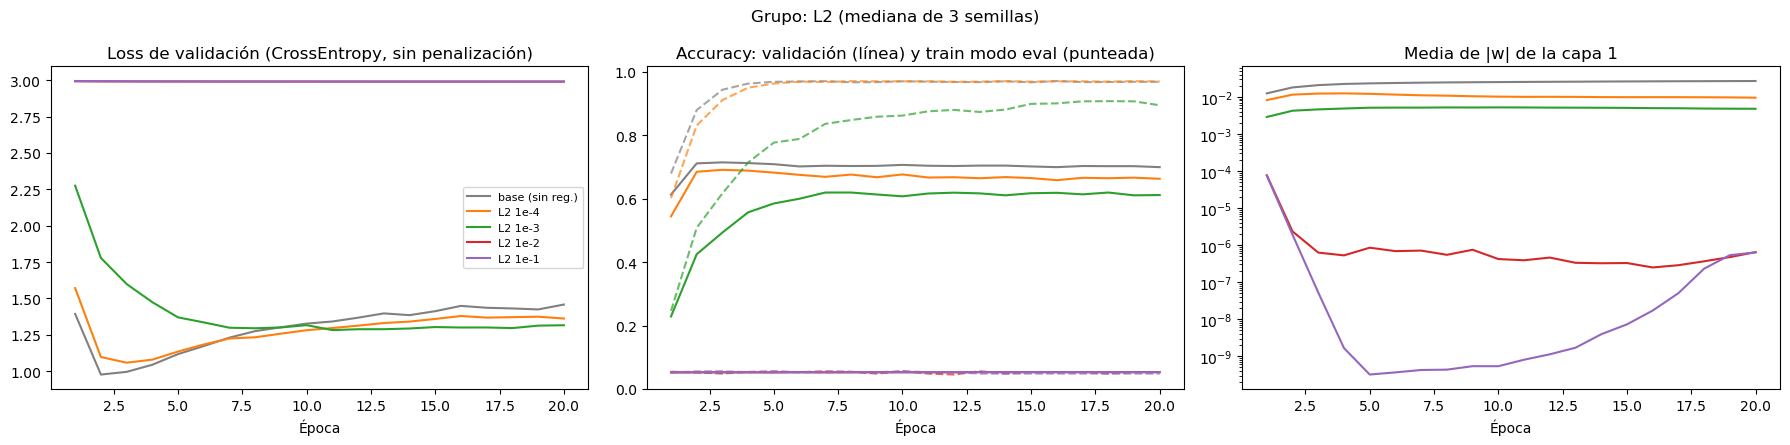

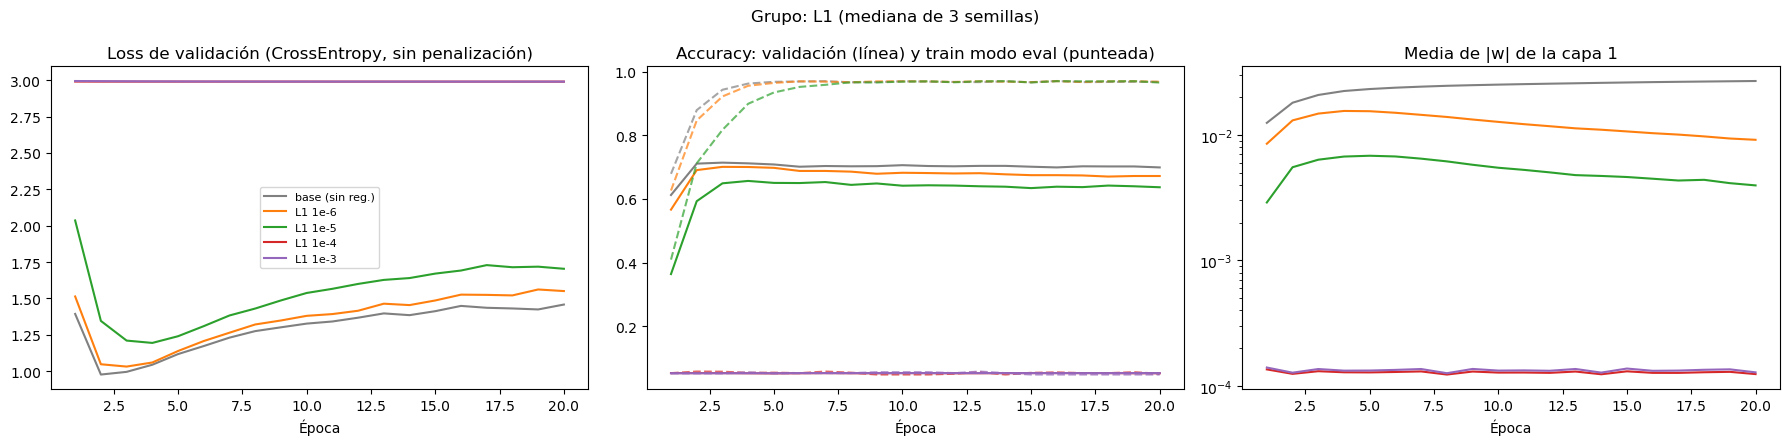

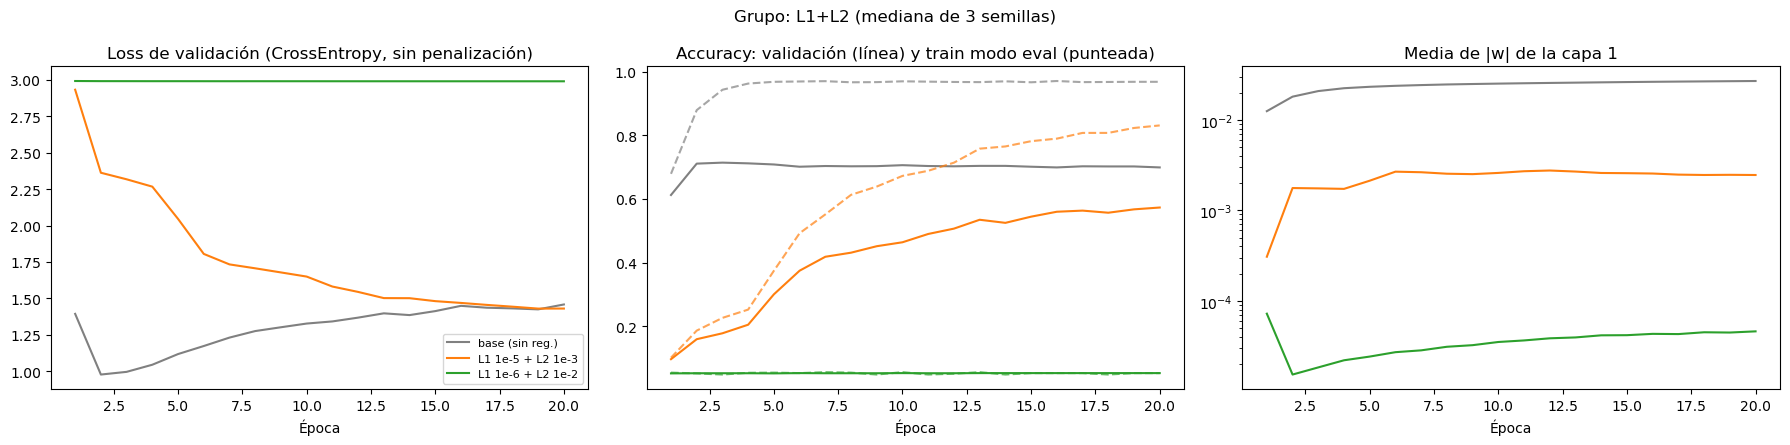

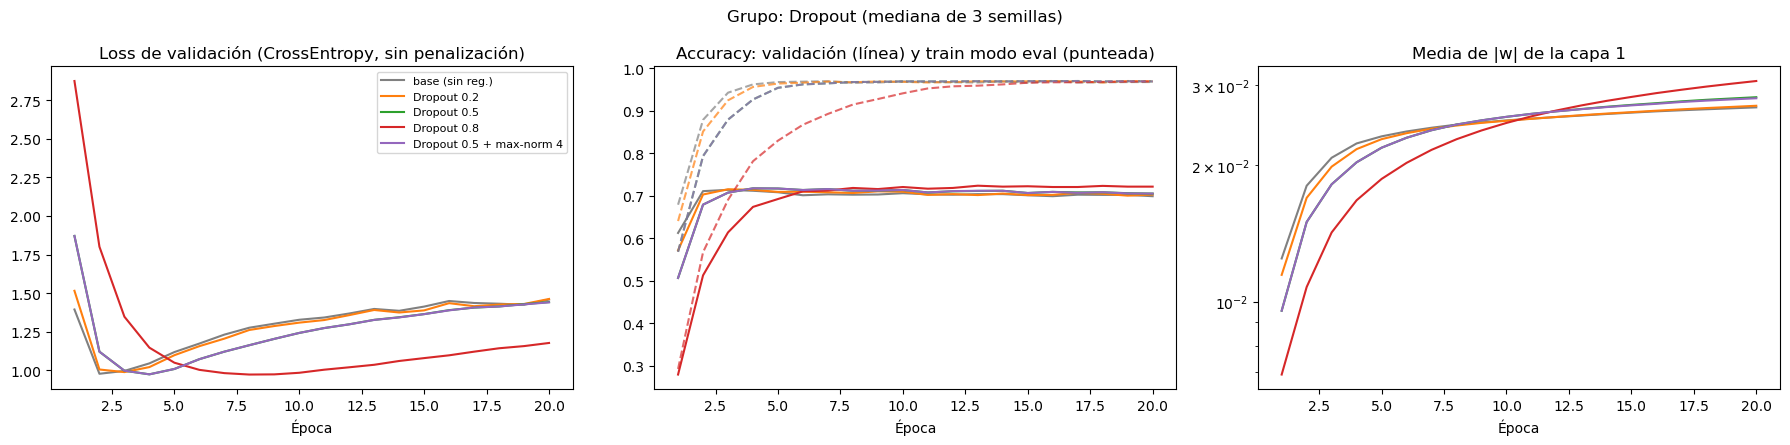

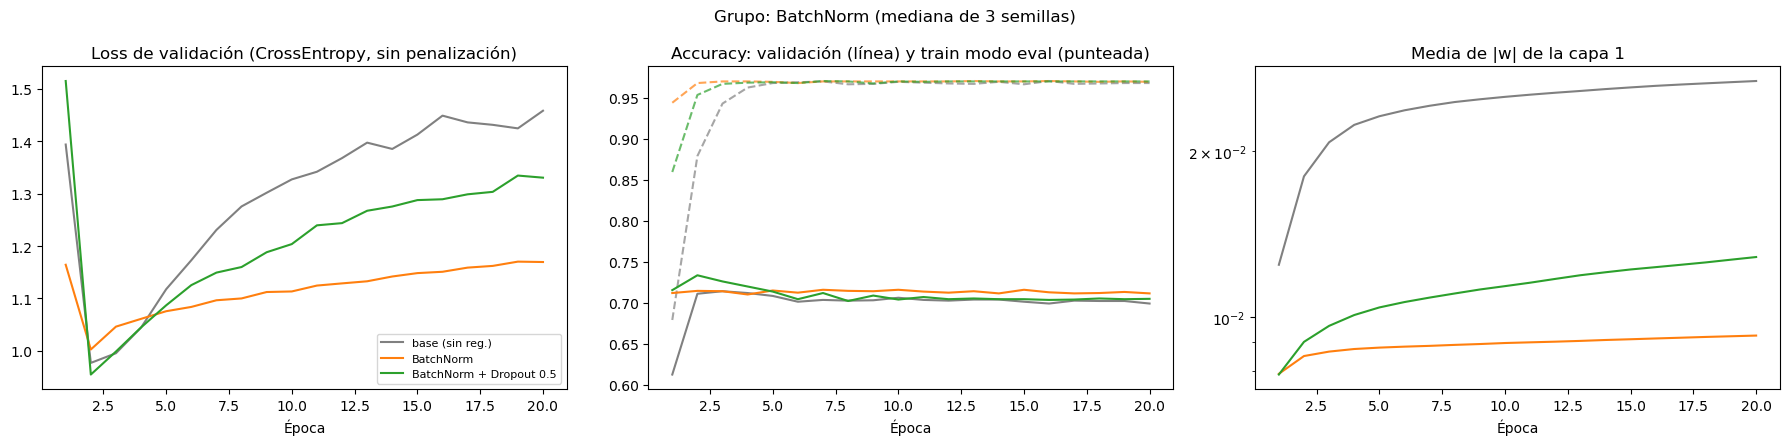

In [42]:
GRUPOS = {}
for n, c in CONFIGS.items():
    GRUPOS.setdefault(c["grupo"], []).append(n)


def curva(nombre, clave, idx_capa=None):
    """Mediana entre semillas de una curva por época."""
    arrs = []
    for s in SEEDS:
        r = resultados.get(f"{nombre}|seed{s}")
        if r is None:
            continue
        v = r[clave]
        if idx_capa is not None:
            v = [x[idx_capa] for x in v]
        arrs.append(np.array(v, dtype=float))
    largo = min(len(a) for a in arrs)
    return np.nanmedian(np.vstack([a[:largo] for a in arrs]), axis=0)


def graficar_grupo(grupo, con_base=True):
    nombres = (["base (sin reg.)"] if con_base and grupo != "Base" else []) + GRUPOS[grupo]
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    for i, n in enumerate(nombres):
        col = "gray" if n == "base (sin reg.)" else f"C{i}"
        ep = np.arange(1, len(curva(n, "val_loss")) + 1)
        axes[0].plot(ep, curva(n, "val_loss"), color=col, label=n)
        axes[1].plot(ep, curva(n, "val_acc"), color=col, label=f"{n} (val)")
        axes[1].plot(ep, curva(n, "train_acc_eval"), color=col, ls="--", alpha=0.7)
        axes[2].plot(ep, curva(n, "mean_abs_capas", 0), color=col, label=n)
    axes[0].set_title("Loss de validación (CrossEntropy, sin penalización)")
    axes[1].set_title("Accuracy: validación (línea) y train modo eval (punteada)")
    axes[2].set_title("Media de |w| de la capa 1")
    axes[2].set_yscale("log")
    for ax in axes:
        ax.set_xlabel("Época")
    axes[0].legend(fontsize=8)
    fig.suptitle(f"Grupo: {grupo} (mediana de {len(SEEDS)} semillas)")
    plt.tight_layout()
    plt.show()


for g in ["L2", "L1", "L1+L2", "Dropout", "BatchNorm"]:
    graficar_grupo(g)

### Análisis 8.1 – Accuracy, sesgo y varianza

**Base (2x512, sin regularización).** La mejor época es la 2: validación 0,711 y train (modo eval) 0,879. Después, la `val_loss` sube de 0,977 a 1,458 en la época 20 y la accuracy de validación baja a 0,699, mientras train sigue subiendo hasta ≈0,97 (gráfico). Es **varianza alta** (sobreajuste), igual que en el TP2. El early stopping ya corta en la época 2, así que la referencia a superar es 0,711.

**L2.**
- λ = 1e-4: validación 0,691 (−2 puntos). Al final sobreajusta menos (`val_loss` en la época 20: 1,362 contra 1,458), pero su mejor punto es peor (0,977 → 1,059).
- λ = 1e-3: validación 0,612 (−10 puntos). La curva de `val_loss` queda casi plana desde la época 7 (1,28 → 1,32), o sea que ya no sobreajusta con las épocas. Pero train también baja: queda en ≈0,89 en la época 20 contra ≈0,97 de la base (gráfico). Subió el **sesgo** y la varianza no bajó: en la época 20, la distancia entre train y validación es ≈0,89 − 0,611 ≈ 0,28, parecida a la de la base (≈0,97 − 0,699 ≈ 0,27).
- λ = 1e-2 y 1e-1: validación y train en 0,053 ≈ 1/20, que es lo que se obtiene adivinando. La `val_loss` queda en 2,990 ≈ ln(20) = 2,996, que es la loss de un modelo que da la misma probabilidad a las 20 clases. Es **sesgo alto**: la red no aprende nada.

**L1.** Pasa lo mismo: λ = 1e-6 da 0,701 (−1 punto), 1e-5 da 0,657, y 1e-4 y 1e-3 quedan en el nivel de adivinar (0,053).

**L1+L2.** (1e-5, 1e-3) da 0,573, peor que L1 1e-5 (0,657) y que L2 1e-3 (0,612) por separado, porque las dos penalizaciones se suman. (1e-6, 1e-2) no aprende, igual que L2 1e-2 solo.

**Con ningún λ probado, L1 o L2 mejoraron la mejor validación, ni achicaron la distancia entre train y validación en accuracy.** Por ejemplo, con L2 1e-4, train termina en ≈0,97 igual que la base (gráfico), pero validación termina más abajo (0,662 contra 0,699). Lo que sí bajó con L2 es la `val_loss` del final (1,362 y 1,316 contra 1,458): ver 8.2.

Dos cosas a tener en cuenta:
1. La penalización suma sobre los 5,04 millones de pesos, mientras que la CrossEntropy es un promedio por documento. Por eso valores de λ que en el ejemplo de clase (una capa oculta de 500 neuronas) eran razonables, como 1e-4, acá ya pesan mucho.
2. *Hipótesis:* muchas palabras del vocabulario aparecen en pocos documentos, así que sus pesos reciben poca "señal" de los datos y la penalización los lleva a cero. Esto es coherente con el 22–41% de pesos casi cero que aparece con L2 (sección 8.2), pero no lo medimos directamente.

Además, la base ya tiene una forma de regularización, el early stopping, que la clase incluye entre las técnicas para la varianza alta.

**Dropout.** Validación 0,715 (p=0,2), 0,718 (p=0,5) y 0,719 (p=0,8) contra 0,711 de la base. Es una mejora chica (+0,4 a +0,75 puntos), pero aparece **en las 3 semillas**: por ejemplo, con p=0,5 da 0,7176 / 0,7221 / 0,7154 contra 0,7106 / 0,7172 / 0,7110 de la base. Con p=0,8 es donde menos sobreajusta al final: en la época 20, `val_loss` 1,177 y validación 0,722, contra 1,458 y 0,699 de la base.

**Max-norm 4 junto a dropout 0,5** da exactamente los mismos números que dropout 0,5 hasta la mejor época, en las 3 semillas. Recién al final se nota una diferencia: `val_loss` en la época 20 de 1,4400 contra 1,4418, y |w| máximo de 0,242 contra 0,280. *Hipótesis:* en las primeras épocas ninguna neurona superó la norma 4, así que el límite no actuó hasta más adelante.

**BatchNorm.** Validación 0,7145 (+0,35 puntos), dentro de la variación entre semillas (desvío 0,008). En la época 2, train ya está en 0,968: es la configuración que **más rápido ajusta train**. **BatchNorm + Dropout 0,5** da 0,7335 (+2,25 puntos sobre la base, mayor en las 3 semillas) y la menor `val_loss` de todas las 2x512 (0,955). En clase se dijo que BN y dropout no se suelen combinar. En este experimento combinarlos no empeoró el resultado: fue la mejor 2x512. Es un solo dataset y una sola red, así que no alcanza para generalizar.

**Referencia TP2 (1x64).** Validación 0,743, más que cualquier 2x512 regularizada. Tiene 597.588 parámetros contra 5.043.220. Achicar la red, que es otra de las soluciones de clase para la varianza alta ("ajustar la cantidad de parámetros"), funcionó mejor que regularizar la red grande.

*Sobre la columna `brecha`:* está medida en la mejor época de cada configuración, que no es la misma para todas (la base la mide en la época 2, cuando train todavía está en 0,879). Por eso, para comparar sobreajuste, se usan además la `val_loss` y la accuracy en la época 20 (`val_loss_ultima`, `val_acc_ultima`).

### 8.2 Valores absolutos de los pesos

Se muestra la media y el máximo de |w| de la capa 1 al final del entrenamiento, el % de pesos con |w| < 1e-3, y el histograma de log10|w| de la capa 1 (semilla 0). En el histograma, cuanto más a la izquierda, más chico es el peso: −3 equivale a |w| = 0,001. La capa 1 tiene la gran mayoría de los parámetros de la red (10.000 × 512).

                                   grupo  mean_abs_capa1  max_abs_capa1  pct_casi_cero_capa1   brecha  val_acc
config                                                                                                        
base (sin reg.)                     Base         0.02680        0.36518              2.21184  0.16800  0.71100
L2 1e-4                               L2         0.00951        0.22572             22.76265  0.21932  0.69068
L2 1e-3                               L2         0.00478        0.21318             40.82524  0.25768  0.61158
L2 1e-2                               L2         0.00000        0.00042            100.00000 -0.00003  0.05303
L2 1e-1                               L2         0.00000        0.00043            100.00000 -0.00453  0.05303
L1 1e-6                               L1         0.00912        0.25713             58.88857  0.22016  0.70084
L1 1e-5                               L1         0.00396        0.37745             72.69529  0.23885  0.65665
L

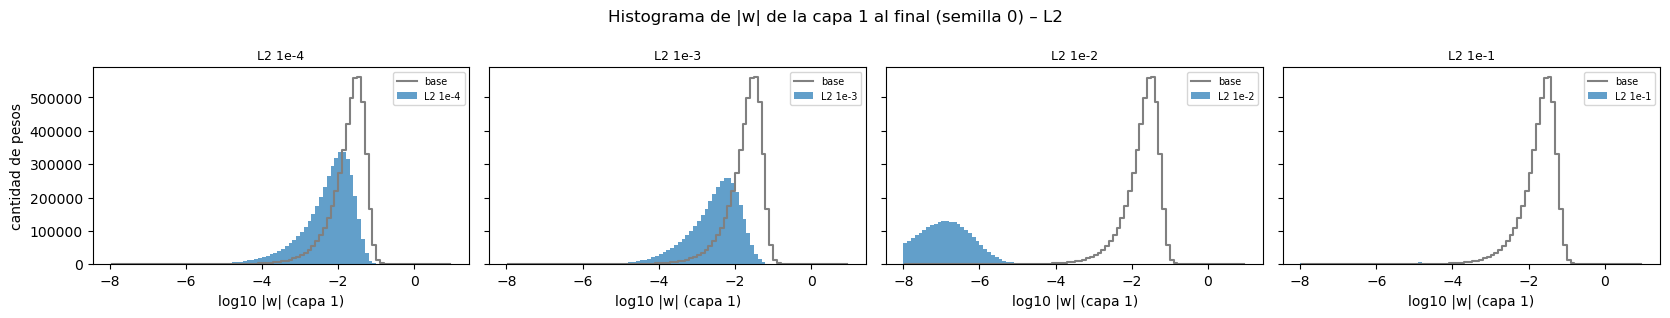

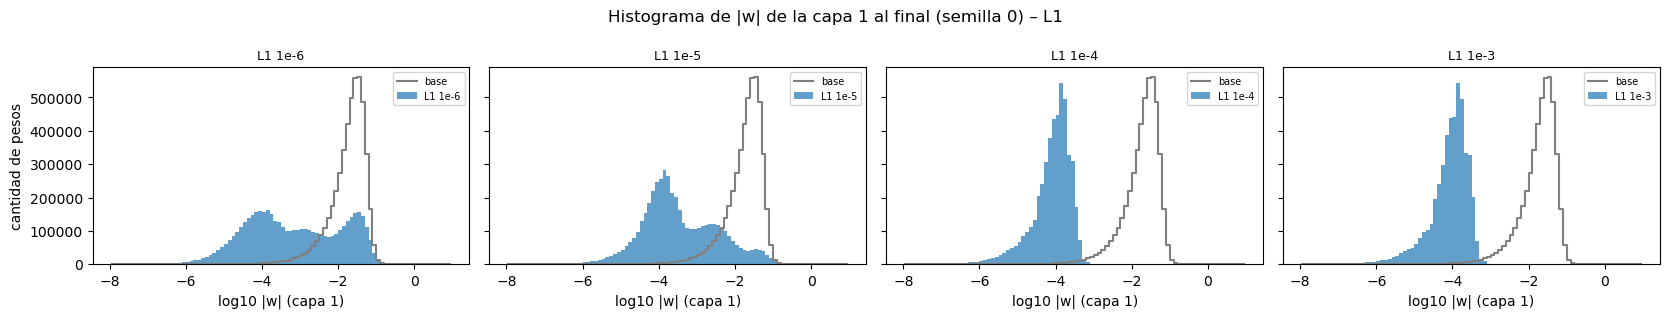

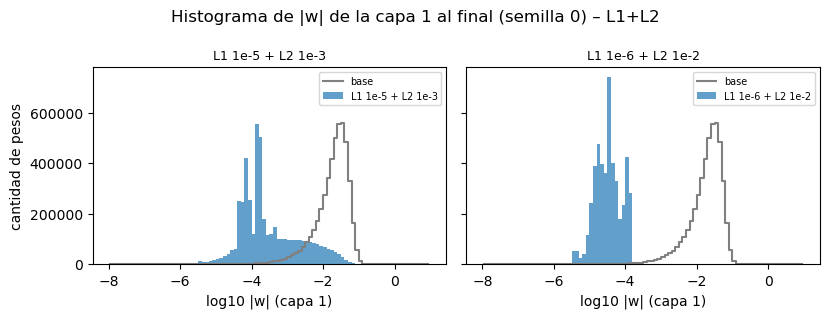

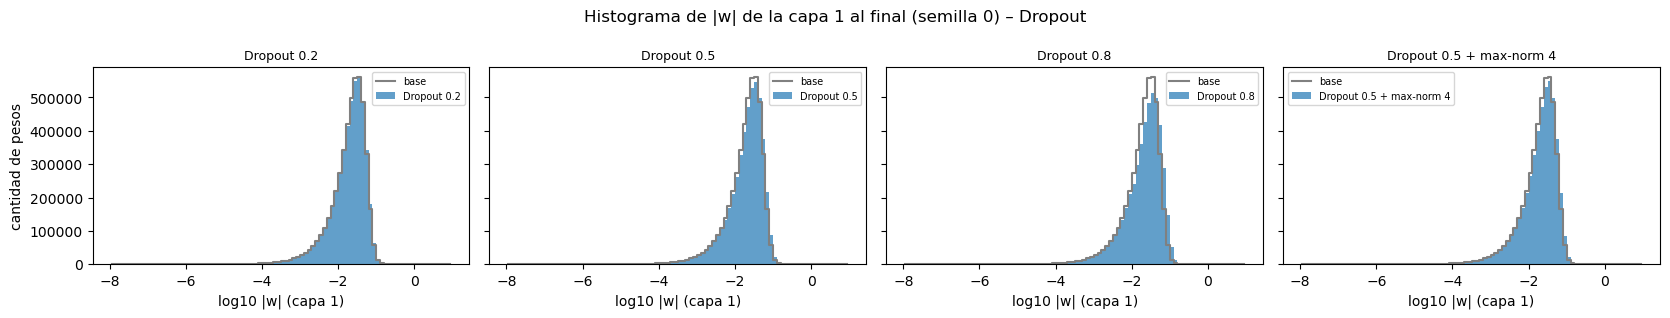

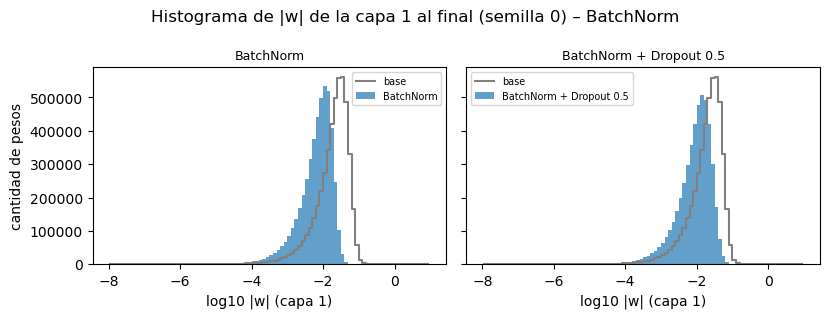

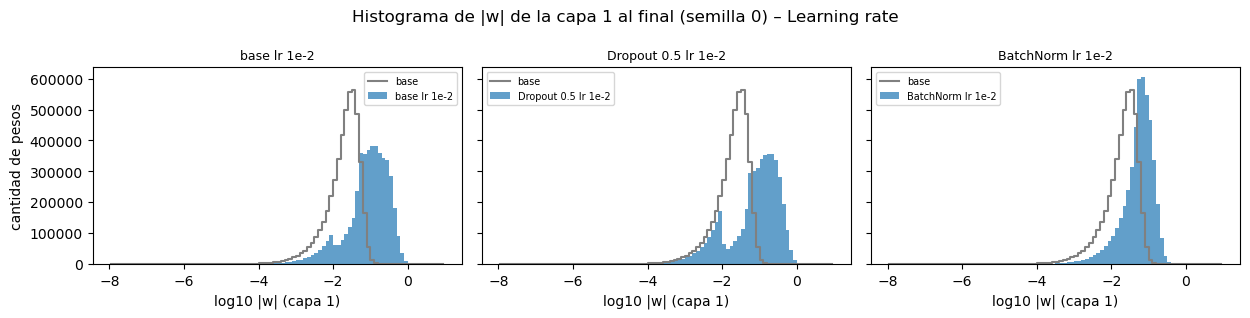

In [43]:
print(resumen[["grupo", "mean_abs_capa1", "max_abs_capa1", "pct_casi_cero_capa1", "brecha", "val_acc"]]
      .round(5).to_string())

centros = (LOG_BINS[:-1] + LOG_BINS[1:]) / 2
base_hist = resultados.get(f"base (sin reg.)|seed{SEEDS[0]}", {}).get("hist_logw_capa1")
for g in ["L2", "L1", "L1+L2", "Dropout", "BatchNorm", "Learning rate"]:
    nombres = GRUPOS[g]
    fig, axes = plt.subplots(1, len(nombres), figsize=(4.2 * len(nombres), 3.2), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, n in zip(axes, nombres):
        hh = resultados.get(f"{n}|seed{SEEDS[0]}", {}).get("hist_logw_capa1")
        if hh is None:
            continue
        if base_hist is not None:
            ax.step(centros, base_hist, where="mid", color="gray", label="base")
        ax.bar(centros, hh, width=LOG_BINS[1] - LOG_BINS[0], alpha=0.7, label=n)
        ax.set_title(n, fontsize=9)
        ax.set_xlabel("log10 |w| (capa 1)")
        ax.legend(fontsize=7)
    axes[0].set_ylabel("cantidad de pesos")
    fig.suptitle(f"Histograma de |w| de la capa 1 al final (semilla {SEEDS[0]}) – {g}")
    plt.tight_layout()
    plt.show()

### Análisis 8.2 – Valores absolutos de los pesos

**Base:** media de |w| en la capa 1 de 0,0268, máximo de 0,365, y 2,2% de pesos con |w| < 1e-3.

**L2: todos los pesos se achican.**
- Al subir λ, la media baja a 0,0095 (λ=1e-4, −65%) y a 0,0048 (λ=1e-3, −82%), y el máximo baja de 0,365 a 0,226 y 0,213.
- En el histograma, la "loma" de los pesos se corre hacia la izquierda y sigue siendo una sola: L2 achica todos los pesos.
- Con λ = 1e-2 o mayor, el 100% de los pesos queda por debajo de 1e-3 (la mayoría cerca de 1e-7). Esto explica por qué ese modelo no aprende (8.1).

**L1: pesos esparsos.**
- El histograma tiene **dos lomas**: una cerca de |w| ≈ 1e-4 (pesos casi anulados) y otra cerca de 1e-2 (pesos que se usan).
- Es lo que se vio en clase: "parámetros muy cercanos a cero pero también con valores altos". El máximo con L1 1e-5 (0,377) es incluso algo mayor que el de la base (0,365).
- **Comparación directa con L2:** L1 1e-6 y L2 1e-4 terminan con casi la misma media de |w| (0,0091 y 0,0095). Pero con L1 el 58,9% de los pesos queda casi en cero, contra el 22,8% con L2. Con L1 1e-5 llega al 72,7%. Es la diferencia vista en clase: L1 empuja a todos los pesos con la misma fuerza y anula muchos, mientras que L2 los achica a todos.
- Los pesos no llegan a 0 exacto sino a ≈1e-4. Por eso se cuentan con un umbral (|w| < 1e-3).

**Dropout: no achica los pesos.** La media queda igual o algo mayor que en la base (0,0270, 0,0282 y 0,0306 para p = 0,2 / 0,5 / 0,8). Lo que baja es el máximo: de 0,365 a 0,264–0,306. Tiene sentido: dropout no agrega ningún término a la función de costo, regulariza de otra forma (agregando ruido). La expectativa de la sección 5, "pesos menos extremos", se cumplió solo para el máximo.

**BatchNorm: pesos más chicos sin penalización.** La media queda en 0,0093 (−65%) y el máximo en 0,133 (−64%), y el gráfico 8.1 muestra que los pesos casi no crecen después de la época 3. Por la fórmula de BN vista en clase, la salida de la capa se divide por su desvío. Entonces, si todos los pesos de una neurona se multiplican por un número, después de normalizar la salida queda igual: la escala la decide γ, no el tamaño de w. *Hipótesis:* por eso los pesos no necesitan crecer.

**Learning rate 1e-2: pesos mucho más grandes.** La media de |w| es entre 3 y 8 veces mayor que con lr 1e-3 (0,085, 0,146 y 0,072) y el máximo llega a 2,26. Esto va de la mano con más sobreajuste (8.4). Coincide con la clase: el overfitting viene acompañado de pesos grandes y de un modelo "muy seguro".

**Conclusión sobre los pesos.** La relación de clase entre pesos grandes y sobreajuste se ve en la **`val_loss`**:
- con lr 1e-2, los pesos son 3 a 8 veces mayores y la `val_loss` final sube a 1,60–2,25;
- con L2, los pesos son más chicos y la `val_loss` final baja (1,362 y 1,316 contra 1,458).

En la **accuracy** no se ve: con L1 o L2, la distancia entre train y validación no se achica (8.1). Esto es coherente con lo visto en clase sobre pesos grandes y un modelo "muy seguro": pesos más chicos dan salidas más chicas antes de la softmax y probabilidades menos extremas. Eso baja la loss de los documentos mal clasificados, pero no cambia necesariamente qué clase se elige. Además, pesos más chicos no garantizan mejor validación: L2 1e-3 tiene media 0,0048 y valida 0,612, mientras que dropout tiene media 0,028 y valida 0,718.

### 8.3 Tiempos de entrenamiento

Para que las mediciones de tiempo sean comparables (pedido del TP2): cada configuración se corre con 3 semillas, se **descarta la primera época** (incluye cargas iniciales) y se toma la **mediana**. Se separan dos cosas distintas:

- **Costo por época** (`s_por_epoca`): cuánto tarda cada pasada por los datos.
- **Velocidad de convergencia** (`epocas_a_70` y `seg_a_70`): cuántas épocas, y cuántos segundos, hacen falta para llegar a 70% de validación.

Para medir bien, conviene no usar la computadora para otra cosa mientras corre.

                                   grupo  s_por_epoca  epocas_a_70  seg_a_70  mejor_epoca  n_parametros
config                                                                                                 
base (sin reg.)                     Base         2.29          2.0      4.58          2.0     5043220.0
L2 1e-4                               L2         3.07          NaN       NaN          3.0     5043220.0
L2 1e-3                               L2         2.89          NaN       NaN         11.0     5043220.0
L2 1e-2                               L2         2.38          NaN       NaN         20.0     5043220.0
L2 1e-1                               L2         2.31          NaN       NaN         20.0     5043220.0
L1 1e-6                               L1         2.12          3.0      6.13          3.0     5043220.0
L1 1e-5                               L1         2.20          NaN       NaN          4.0     5043220.0
L1 1e-4                               L1         2.10          N

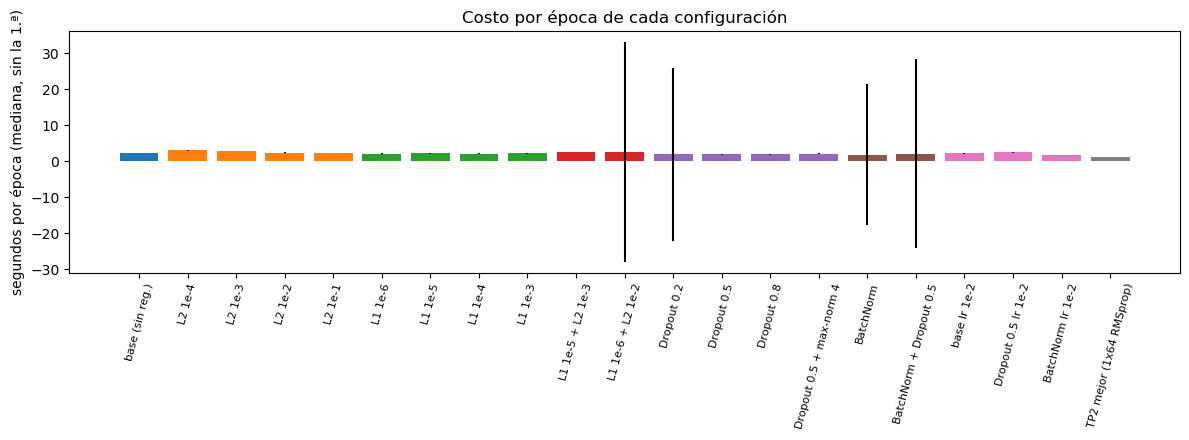

In [44]:
print(resumen[["grupo", "s_por_epoca", "epocas_a_70", "seg_a_70", "mejor_epoca", "n_parametros"]]
      .round(2).to_string())

desvio_t = df_b.groupby("config", observed=True)["s_por_epoca"].std()
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(range(len(resumen)), resumen["s_por_epoca"], yerr=desvio_t.reindex(resumen.index).fillna(0),
       color=[f"C{list(GRUPOS).index(g)}" for g in resumen["grupo"]])
ax.set_xticks(range(len(resumen)), resumen.index, rotation=75, fontsize=8)
ax.set_ylabel("segundos por época (mediana, sin la 1.ª)")
ax.set_title("Costo por época de cada configuración")
plt.tight_layout()
plt.show()

### Análisis 8.3 – Tiempos

**Costo por época: no se puede atribuir a la técnica.** Las medianas van de 1,8 a 3,1 s por época, pero sin un patrón que coincida con el trabajo extra de cada técnica:
- BN (1,84 s) y dropout (1,86 s) salieron *más rápidos* que la base (2,29 s), aunque agregan operaciones.
- L2 1e-4 (3,07 s) salió más lento que L1 1e-4 (2,10 s), aunque el cálculo es casi el mismo.

Durante la corrida hubo interrupciones. La mayoría de las corridas tardaron 40–110 s, pero algunas tardaron mucho más: Dropout 0,2 semilla 0 (825 s), BatchNorm semilla 2 (736 s), L1+L2 semilla 2 (1.130 s) y BN + Dropout semilla 0 (1.204 s). En el entrenamiento final, la misma configuración midió 26,5 y 21,0 s por época en dos semillas y 1,52 s en la tercera. Por eso, **diferencias de menos de ~1 s por época no se pueden atribuir a la técnica**. Lo que sí se puede decir es que, en esta máquina, el costo extra por época de estas técnicas es chico comparado con el ruido de la medición.

**Velocidad de convergencia (en épocas): sí se puede comparar,** porque contar épocas no depende de lo que esté corriendo en paralelo.
- **BatchNorm** llega a 70% de validación en **1 época** (la base en 2). Train en modo eval ya está en ≈0,95 en la época 1 (gráfico 8.5), contra ≈0,68 de la base. Coincide con la clase: BN es sobre todo una técnica para **acelerar el entrenamiento**. Tiempo hasta 70%: 1,84 s contra 4,58 s de la base.
- **Dropout** necesita **más épocas** cuanto más alto es p: llega a 70% en 2, 3 y 6 épocas, y su mejor época es la 3, 4 y 8 (p = 0,2 / 0,5 / 0,8). Coincide con la clase, donde con dropout hubo que pasar de 2.000 a 4.000 épocas. Al anular neuronas, cada paso usa solo una parte de la red y el aprendizaje avanza más lento.
- **L1/L2:** con L1 ≥ 1e-5 o L2 ≥ 1e-4, la validación nunca llega a 70%. Con L2 1e-3, la mejor época se corre a la 11–14.
- **Red chica (referencia TP2, 1x64):** 1,11 s por época, con 8 veces menos parámetros, y llega a 70% en 3 épocas.

### 8.4 Learning rate

Se comparan la base, dropout 0.5 y BatchNorm con el lr de la base (1e-3) y con un lr 10 veces mayor (1e-2). La clase recomienda subir el lr con dropout, y BN debería permitir lr más altos sin que el entrenamiento se vuelva inestable.

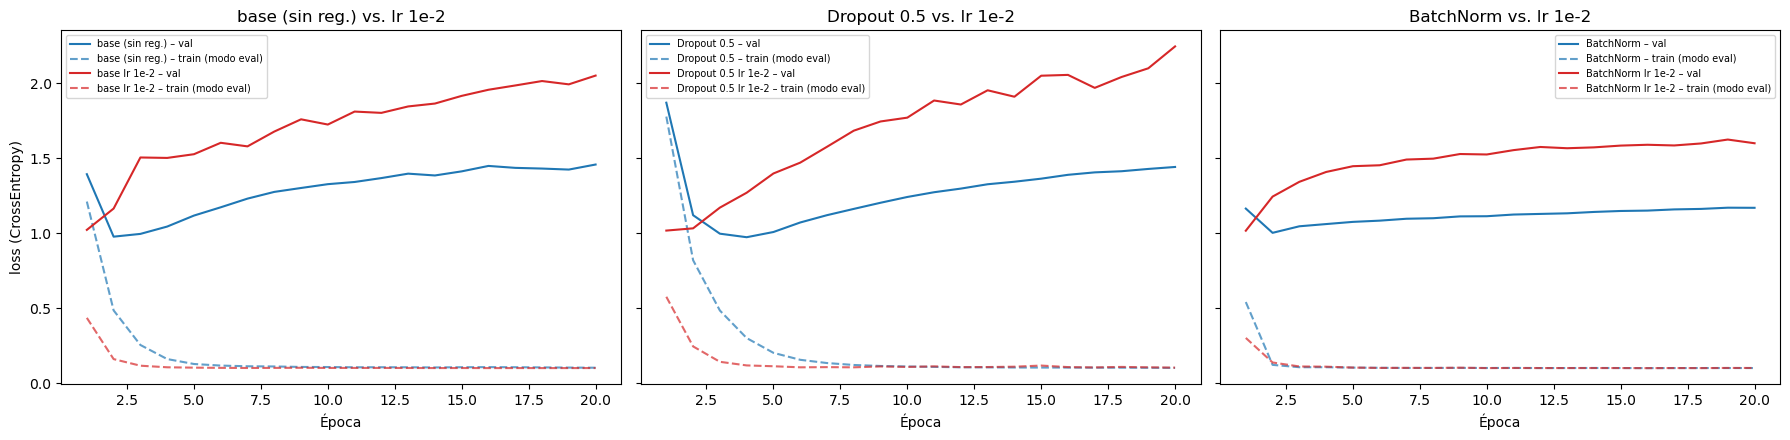

                     mejor_epoca  val_acc  val_acc_desvio  brecha  val_loss_min  epocas_a_70  ruido_val_loss  mean_abs_capa1
config                                                                                                                      
base (sin reg.)              2.0   0.7110          0.0037  0.1680        0.9771          2.0          0.0287          0.0268
base lr 1e-2                 1.0   0.6955          0.0052  0.1921        1.0223          4.0          0.1025          0.0852
Dropout 0.5                  4.0   0.7176          0.0034  0.2076        0.9734          3.0          0.0392          0.0282
Dropout 0.5 lr 1e-2          1.0   0.6947          0.0131  0.1398        1.0176          2.0          0.0765          0.1464
BatchNorm                    2.0   0.7145          0.0080  0.2540        1.0026          1.0          0.0099          0.0093
BatchNorm lr 1e-2            1.0   0.7053          0.0047  0.2268        1.0168          1.0          0.0330          0.0721


In [45]:
pares = [("base (sin reg.)", "base lr 1e-2"), ("Dropout 0.5", "Dropout 0.5 lr 1e-2"), ("BatchNorm", "BatchNorm lr 1e-2")]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, (a, b) in zip(axes, pares):
    for n, col in [(a, "C0"), (b, "C3")]:
        ep = np.arange(1, len(curva(n, "val_loss")) + 1)
        ax.plot(ep, curva(n, "val_loss"), color=col, label=f"{n} – val")
        ax.plot(ep, curva(n, "train_loss_eval"), color=col, ls="--", alpha=0.7, label=f"{n} – train (modo eval)")
    ax.set_title(f"{a} vs. lr 1e-2")
    ax.set_xlabel("Época")
    ax.legend(fontsize=7)
axes[0].set_ylabel("loss (CrossEntropy)")
plt.tight_layout()
plt.show()

print(resumen.loc[[x for p in pares for x in p],
                  ["mejor_epoca", "val_acc", "val_acc_desvio", "brecha", "val_loss_min", "epocas_a_70",
                   "ruido_val_loss", "mean_abs_capa1"]].round(4).to_string())

### Análisis 8.4 – Learning rate

**Con lr 1e-2 (×10), las tres configuraciones empeoran.** Las tres tienen su mejor época en la 1 y después la `val_loss` sube rápido (gráfico):

| | lr 1e-3 | lr 1e-2 |
|---|---|---|
| Base: validación / `val_loss` época 20 | 0,711 / 1,46 | 0,696 / 2,05 |
| Dropout 0,5 | 0,718 / 1,44 | 0,695 / 2,25 |
| BatchNorm | 0,715 / 1,17 | 0,705 / 1,60 |

Además, los pesos crecen entre 3 y 8 veces (8.2) y el `ruido_val_loss` se multiplica: 0,029 → 0,103 (base), 0,039 → 0,077 (dropout) y 0,010 → 0,033 (BN). Con lr 1e-2, ya en la época 2 la loss de train (modo eval) está entre 0,13 y 0,25: el modelo memoriza train casi de inmediato.

**La recomendación de clase de subir el lr ×10 con dropout no funcionó acá.** *Hipótesis:* esa recomendación viene de entrenar con SGD + momentum, donde el paso depende directamente del lr. Acá se usa Adam, que ya ajusta el tamaño del paso de cada peso, y con lr 1e-3 la red ya converge en 2–4 épocas, así que no le faltaba velocidad.

**BatchNorm fue la que mejor toleró el lr alto.** Perdió 1 punto, contra 1,5 y 2,3 de la base y del dropout. También fue la menos ruidosa y la más estable entre semillas (desvío 0,0047, contra 0,0131 de dropout con lr 1e-2). Coincide con la clase: BN estabiliza el entrenamiento.

**En Optuna** (gráfico 10), los 10 mejores trials usaron lr entre 3,0e-4 y 7,4e-3. Ningún trial completo con lr por encima de ≈2e-2 superó 0,65 de validación.

### 8.5 Ruido en las curvas

Tres medidas de ruido:

- `ruido_batch`: desvío de la loss entre los batches de una misma época (promedio de las épocas, sin la 1.ª).
- `ruido_val_loss`: desvío de los cambios de `val_loss` de una época a la siguiente. Una curva que sube y baja da un valor alto.
- `dif_train_modo`: accuracy de train en modo evaluación menos accuracy de train medida durante el entrenamiento. Con dropout, durante el entrenamiento se anulan neuronas, así que se espera que la segunda sea más baja.

                                   grupo  ruido_batch  ruido_val_loss  dif_train_modo  val_acc
config                                                                                        
base (sin reg.)                     Base       0.0532          0.0287          0.0069   0.7110
L2 1e-4                               L2       0.0559          0.0256          0.0129   0.6907
L2 1e-3                               L2       0.1107          0.0568          0.0776   0.6116
L2 1e-2                               L2       0.0068          0.0001          0.0031   0.0530
L2 1e-1                               L2       0.0064          0.0002          0.0016   0.0530
L1 1e-6                               L1       0.0543          0.0285          0.0100   0.7008
L1 1e-5                               L1       0.0631          0.0471          0.0240   0.6567
L1 1e-4                               L1       0.0080          0.0001          0.0037   0.0526
L1 1e-3                               L1       0.0

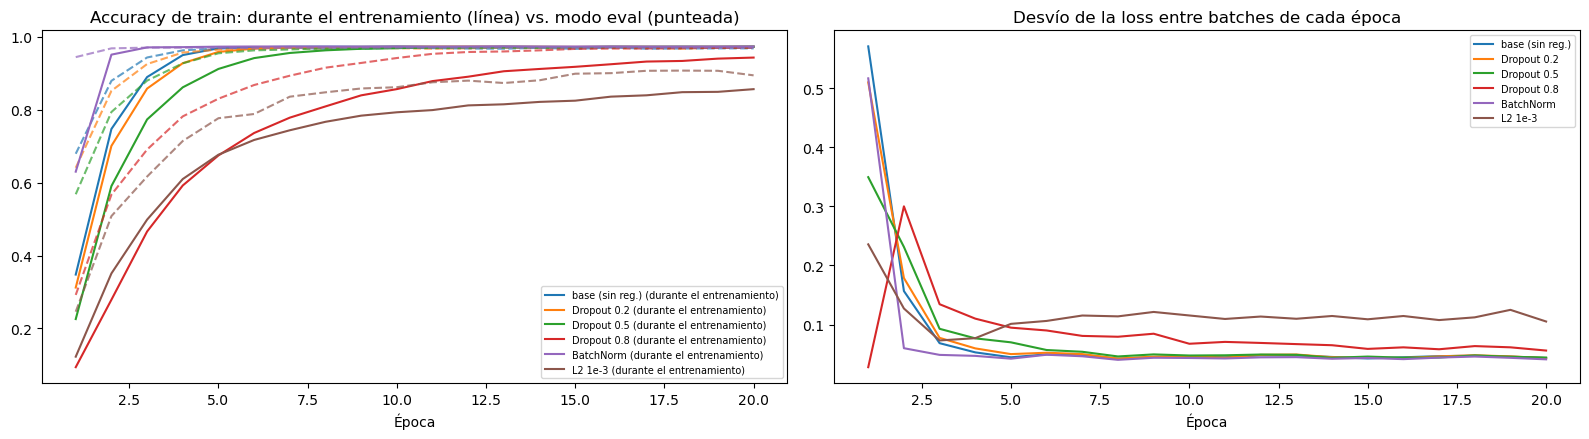

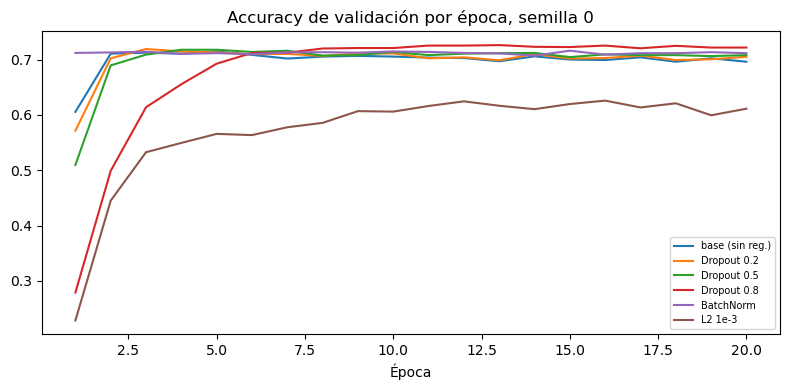

In [46]:
print(resumen[["grupo", "ruido_batch", "ruido_val_loss", "dif_train_modo", "val_acc"]].round(4).to_string())

sel = ["base (sin reg.)", "Dropout 0.2", "Dropout 0.5", "Dropout 0.8", "BatchNorm", "L2 1e-3"]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for i, n in enumerate(sel):
    ep = np.arange(1, len(curva(n, "train_acc")) + 1)
    axes[0].plot(ep, curva(n, "train_acc"), color=f"C{i}", label=f"{n} (durante el entrenamiento)")
    axes[0].plot(ep, curva(n, "train_acc_eval"), color=f"C{i}", ls="--", alpha=0.7)
    axes[1].plot(ep, curva(n, "batch_loss_std"), color=f"C{i}", label=n)
axes[0].set_title("Accuracy de train: durante el entrenamiento (línea) vs. modo eval (punteada)")
axes[1].set_title("Desvío de la loss entre batches de cada época")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# Una semilla sola (sin promediar) para ver el ruido "crudo" de la validación
fig, ax = plt.subplots(figsize=(8, 4))
for i, n in enumerate(sel):
    r = resultados.get(f"{n}|seed{SEEDS[0]}")
    if r is not None:
        ax.plot(range(1, len(r["val_acc"]) + 1), r["val_acc"], color=f"C{i}", label=n)
ax.set_title(f"Accuracy de validación por época, semilla {SEEDS[0]}")
ax.set_xlabel("Época")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### Análisis 8.5 – Ruido en las curvas

**Dropout.**
- La accuracy de train medida *durante* el entrenamiento queda por debajo de la medida en modo evaluación, y la diferencia crece con p: `dif_train_modo` = 0,011 / 0,022 / 0,098 (p = 0,2 / 0,5 / 0,8), contra 0,007 de la base. Con p=0,8, en el gráfico la curva de train "en entrenamiento" queda claramente debajo de la punteada durante todas las épocas. Esto pasa porque durante el entrenamiento se anulan neuronas, así que el modelo rinde menos que al evaluar. Coincide con la observación de clase de que, con dropout, la accuracy de train es mucho más ruidosa que la de validación.
- El ruido entre batches también crece con p: `ruido_batch` = 0,055 / 0,063 / 0,088, contra 0,053 de la base.
- `ruido_val_loss` crece igual (0,026 / 0,039 / 0,118), pero ojo: con p=0,8 parte de ese valor viene de la bajada inicial de la curva (1,8 → 1,35 → 1,15 en las épocas 2–4), no de subidas y bajadas.

**BatchNorm.** Como en el ejemplo de clase, donde con BN la validación salía "menos ruidosa", acá tiene la curva de validación más suave de todas (`ruido_val_loss` 0,0099 contra 0,029 de la base) y menos ruido entre batches (0,044 contra 0,053). Train medida en entrenamiento y en evaluación casi coinciden (`dif_train_modo` = −0,002). La clase menciona que las estadísticas de cada mini-batch agregan algo de ruido. Con estas medidas no se observa: si existe, es menor que el resto de las fuentes de ruido.

**L2 1e-3** es la configuración con más ruido entre batches (0,111, el doble de la base), y se mantiene alto en todas las épocas (gráfico). *Hipótesis:* como este modelo no llega a memorizar train (≈0,90), en cada batch hay documentos mal clasificados con loss alta mezclados con otros bien clasificados, y eso hace variar la loss entre batches. En la base, que memoriza train, casi todas las losses de train quedan cerca de su mínimo. La misma idea explicaría parte del ruido de dropout 0,8.

**Learning rate 1e-2:** como se vio en 8.4, la `val_loss` sube y baja mucho más (`ruido_val_loss` ×2 a ×3,6).

## 9. Búsqueda conjunta con Optuna

Los barridos muestran el efecto de cada técnica por separado. La búsqueda con Optuna incluye **todos los hiperparámetros a la vez**: los del TP1 (preprocesamiento), los del TP2 (arquitectura y optimizador) y los nuevos de regularización.

| Grupo | Hiperparámetro | Valores | Escala |
|---|---|---|---|
| Preprocesamiento (TP1) | `remove_stopwords` | True / False | categórica |
| | `normalization` | none / stem / lemmatize | categórica |
| | `ngram_range` | 1gram / 1_2gram | categórica |
| | `max_features` | 2.000 / 5.000 / 10.000 | categórica |
| | `min_df` | 1 / 2 / 5 | categórica |
| Arquitectura (TP2) | `n_layers` | 1 a 3 | entera |
| | `n_units` (todas las capas iguales) | 64 / 128 / 256 / 512 | categórica |
| | `activation` | relu / leaky_relu / tanh / sigmoid | categórica |
| Optimizador (TP2) | `optimizer` | adam / rmsprop / sgd | categórica |
| | `lr` | 1e-4 a 1e-1 | **log** |
| | Adam: `beta1` | 0,8 a 0,99 | lineal |
| | Adam: `1 − beta2` | 1e-4 a 1e-1 (beta2 de 0,9 a 0,9999) | **log** |
| | RMSprop: `alpha`, `momentum` | 0,8–0,99 y 0–0,9 | lineal |
| | SGD: `momentum` | 0 a 0,99 | lineal |
| | `batch_size` | 32 / 64 / 128 / 256 | categórica |
| Regularización (nuevo) | `reg_type` | none / l1 / l2 / l1_l2 | categórica |
| | `l1_lambda` (si hay L1) | 1e-7 a 1e-4 | **log** |
| | `l2_lambda` (si hay L2) | 1e-6 a 1e-1 | **log** |
| | `dropout` | 0 a 0,7 | lineal |
| | `dropout_in` | 0 / 0,2 | categórica |
| | `batchnorm` | True / False | categórica |
| | `max_norm` | 0 (sin) / 3 / 5 | categórica |

**Por qué escala log** en lr, λ y 1−beta2: lo que importa es el orden de magnitud. Pasar de 1e-4 a 1e-3 cambia tanto como pasar de 1e-3 a 1e-2. En escala lineal, casi todos los valores probados caerían en la década más alta. Con beta2 pasa algo parecido: 0,99 y 0,999 parecen cercanos, pero el promedio de Adam recuerda unos 100 y 1.000 pasos respectivamente. Por eso se muestrea 1−beta2 en escala log.

**Por qué `n_units` es uno solo para todas las capas**: con unos 50-60 trials, un valor por capa agrega muchos hiperparámetros que se prueban pocas veces cada uno. En el TP2, `n_units_l2` tuvo menos de 2 trials en algunos valores.

**Presupuesto y reproducibilidad**: todos los trials usan 15 épocas. Se usa el sampler TPE con **semilla fija**, y MedianPruner (no corta nada en los primeros 8 trials ni en las primeras 4 épocas de cada trial). La búsqueda termina a los 60 trials o a los 40 minutos, lo que pase primero, para no pasarse del tiempo. El valor que se optimiza es la accuracy de validación **en la época de menor val_loss**, que es la época que elegiría el early stopping. La búsqueda se guarda en una base SQLite, así que si se corta se retoma.

In [47]:
def config_desde_params(p):
    """Convierte los parámetros de un trial en (cfg, preprocesamiento)."""
    if p["optimizer"] == "adam":
        opt_kw = dict(beta1=p["beta1"], beta2=1 - p["one_minus_beta2"])
    elif p["optimizer"] == "rmsprop":
        opt_kw = dict(alpha=p["rmsprop_alpha"], momentum=p["rmsprop_momentum"])
    else:
        opt_kw = dict(momentum=p["sgd_momentum"])
    c = dict(hidden=[p["n_units"]] * p["n_layers"], act=p["activation"], opt=p["optimizer"], lr=p["lr"],
             bs=p["batch_size"], opt_kw=opt_kw,
             l1=p["l1_lambda"] if p["reg_type"] in ("l1", "l1_l2") else 0.0,
             l2=p["l2_lambda"] if p["reg_type"] in ("l2", "l1_l2") else 0.0,
             dropout=p["dropout"], dropout_in=p["dropout_in"], bn=p["batchnorm"],
             max_norm=float(p["max_norm"]), grupo="Optuna")
    pre = dict(sw=p["remove_stopwords"], norm=p["normalization"], ngram=p["ngram_range"],
               max_features=p["max_features"], min_df=p["min_df"])
    return c, pre


def objective(trial):
    p = {}
    # Preprocesamiento (TP1)
    p["remove_stopwords"] = trial.suggest_categorical("remove_stopwords", [False, True])
    p["normalization"] = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    p["ngram_range"] = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    p["max_features"] = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    p["min_df"] = trial.suggest_categorical("min_df", [1, 2, 5])
    # Arquitectura (TP2)
    p["n_layers"] = trial.suggest_int("n_layers", 1, 3)
    p["n_units"] = trial.suggest_categorical("n_units", [64, 128, 256, 512])
    p["activation"] = trial.suggest_categorical("activation", ["relu", "leaky_relu", "tanh", "sigmoid"])
    # Optimizador (TP2)
    p["optimizer"] = trial.suggest_categorical("optimizer", ["adam", "rmsprop", "sgd"])
    p["lr"] = trial.suggest_float("lr", 1e-4, 1e-1, log=True)
    if p["optimizer"] == "adam":
        p["beta1"] = trial.suggest_float("beta1", 0.8, 0.99)
        p["one_minus_beta2"] = trial.suggest_float("one_minus_beta2", 1e-4, 1e-1, log=True)
    elif p["optimizer"] == "rmsprop":
        p["rmsprop_alpha"] = trial.suggest_float("rmsprop_alpha", 0.8, 0.99)
        p["rmsprop_momentum"] = trial.suggest_float("rmsprop_momentum", 0.0, 0.9)
    else:
        p["sgd_momentum"] = trial.suggest_float("sgd_momentum", 0.0, 0.99)
    p["batch_size"] = trial.suggest_categorical("batch_size", [32, 64, 128, 256])
    # Regularización (nuevo)
    p["reg_type"] = trial.suggest_categorical("reg_type", ["none", "l1", "l2", "l1_l2"])
    if p["reg_type"] in ("l1", "l1_l2"):
        p["l1_lambda"] = trial.suggest_float("l1_lambda", 1e-7, 1e-4, log=True)
    if p["reg_type"] in ("l2", "l1_l2"):
        p["l2_lambda"] = trial.suggest_float("l2_lambda", 1e-6, 1e-1, log=True)
    p["dropout"] = trial.suggest_float("dropout", 0.0, 0.7)
    p["dropout_in"] = trial.suggest_categorical("dropout_in", [0.0, 0.2])
    p["batchnorm"] = trial.suggest_categorical("batchnorm", [False, True])
    p["max_norm"] = trial.suggest_categorical("max_norm", [0, 3, 5])

    c, pre = config_desde_params(p)
    X_tr, X_val, _, _ = vectorizar(**pre)
    ds_tr, ds_val = a_tensores(X_tr, y_tr), a_tensores(X_val, y_val)
    h, _, _ = correr_config(c, ds_tr, ds_val, SEED, EPOCHS_OPTUNA, trial=trial)

    be = h["mejor_epoca"]
    t = np.array(h["epoch_time"])
    trial.set_user_attr("mejor_epoca", None if be is None else be + 1)
    trial.set_user_attr("s_por_epoca", float(np.median(t[1:])) if len(t) > 1 else float(t[0]))
    trial.set_user_attr("n_parametros", h["n_parametros"])
    if be is None:
        return 0.0
    trial.set_user_attr("val_loss_min", h["val_loss"][be])
    trial.set_user_attr("train_acc_eval", h["train_acc_eval"][be])
    return h["val_acc"][be]


ds_tr_b = ds_val_b = None      # libera memoria de los barridos
gc.collect()

study = optuna.create_study(
    study_name=f"tp3_{SUFIJO}", storage=f"sqlite:///optuna_tp3_{SUFIJO}.db", load_if_exists=True,
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=4),
)
hechos = [t for t in study.trials if t.state in (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED)]
restantes = N_TRIALS - len(hechos)
print(f"Trials ya hechos: {len(hechos)} | por hacer: {max(restantes, 0)}")
t0 = time.time()
if restantes > 0:
    study.optimize(objective, n_trials=restantes, timeout=OPTUNA_TIMEOUT_S, catch=(RuntimeError, ValueError))
print(f"Tiempo de la búsqueda en esta sesión: {(time.time() - t0) / 60:.1f} min")

completos = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
if not completos:
    raise RuntimeError("Ningún trial terminó bien: revisar los errores de arriba.")
print("Mejor val_acc:", round(study.best_value, 4))
print("Mejores hiperparámetros:", study.best_params)

[I 2026-11-18 12:58:47,280] A new study created in RDB with name: tp3_completo


Trials ya hechos: 0 | por hacer: 60


[I 2026-11-18 12:58:58,087] Trial 0 finished with value: 0.6106937693327441 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'n_layers': 1, 'n_units': 512, 'activation': 'tanh', 'optimizer': 'sgd', 'lr': 0.0226739865237804, 'sgd_momentum': 0.19767704433677613, 'batch_size': 256, 'reg_type': 'l1_l2', 'l1_lambda': 2.661901888489056e-05, 'l2_lambda': 3.334792728637589e-05, 'dropout': 0.0683704798044687, 'dropout_in': 0.0, 'batchnorm': True, 'max_norm': 3}. Best is trial 0 with value: 0.6106937693327441.
[I 2026-11-18 13:10:49,737] Trial 1 finished with value: 0.6416261599646487 and parameters: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 1, 'n_layers': 1, 'n_units': 512, 'activation': 'tanh', 'optimizer': 'sgd', 'lr': 0.020736445177905044, 'sgd_momentum': 0.19672852471883068, 'batch_size': 64, 'reg_type': 'none', 'dropout': 0.6041723981129155, 'drop

Tiempo de la búsqueda en esta sesión: 40.2 min
Mejor val_acc: 0.7521
Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 1, 'n_layers': 1, 'n_units': 256, 'activation': 'leaky_relu', 'optimizer': 'adam', 'lr': 0.0011278256331487544, 'beta1': 0.9241879220137176, 'one_minus_beta2': 0.0002623701479138782, 'batch_size': 128, 'reg_type': 'none', 'dropout': 0.5098003789801987, 'dropout_in': 0.0, 'batchnorm': False, 'max_norm': 0}


## 10. Análisis de la búsqueda de hiperparámetros

In [48]:
df_t = study.trials_dataframe()
df_t["duracion_s"] = df_t["duration"].dt.total_seconds()

print("Estados de los trials:")
print(df_t["state"].value_counts().to_string(), "\n")
print("Duración (s) mediana por estado:")
print(df_t.groupby("state")["duracion_s"].median().round(1).to_string(), "\n")

comp = df_t[df_t["state"] == "COMPLETE"].sort_values("value", ascending=False)
cols_t = [c for c in ["number", "value", "user_attrs_mejor_epoca", "user_attrs_train_acc_eval", "duracion_s",
                      "params_n_layers", "params_n_units", "params_activation", "params_optimizer", "params_lr",
                      "params_batch_size", "params_reg_type", "params_l1_lambda", "params_l2_lambda",
                      "params_dropout", "params_dropout_in", "params_batchnorm", "params_max_norm",
                      "params_normalization", "params_ngram_range", "params_max_features"] if c in comp.columns]
print("Top 10 trials completos:")
print(comp[cols_t].head(10).to_string(index=False))

try:
    importancias = optuna.importance.get_param_importances(study)
    print("\nImportancia de cada hiperparámetro (cuánto de la variación de val_acc explica):")
    for k, v in importancias.items():
        print(f"  {k:20s} {v:.3f}")
except Exception as e:
    importancias = {}
    print("No se pudo calcular la importancia:", e)

Estados de los trials:
state
COMPLETE    32
PRUNED      16 

Duración (s) mediana por estado:
state
COMPLETE    26.1
PRUNED       8.0 

Top 10 trials completos:
 number    value  user_attrs_mejor_epoca  user_attrs_train_acc_eval  duracion_s  params_n_layers  params_n_units params_activation params_optimizer  params_lr  params_batch_size params_reg_type  params_l1_lambda  params_l2_lambda  params_dropout  params_dropout_in  params_batchnorm  params_max_norm params_normalization params_ngram_range  params_max_features
     40 0.752099                     9.0                     0.9575   19.994460                1             256        leaky_relu             adam   0.001128                128            none               NaN               NaN        0.509800                0.0             False                0                 stem              1gram                10000
     25 0.751657                     4.0                     0.9380   49.611383                1             512     

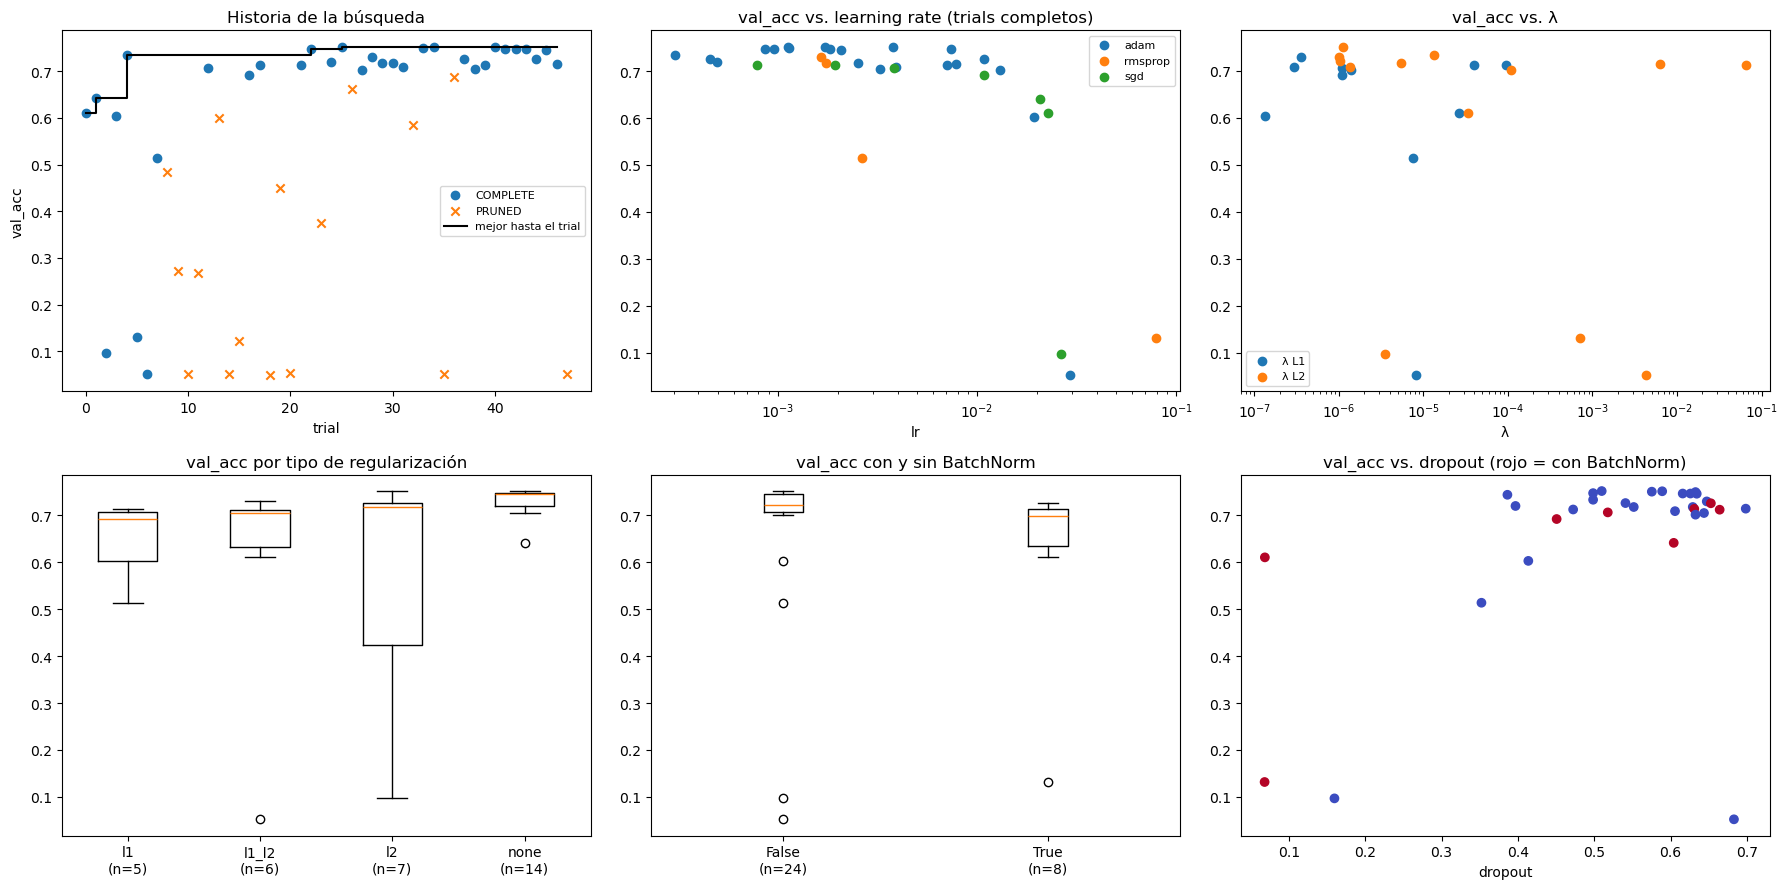

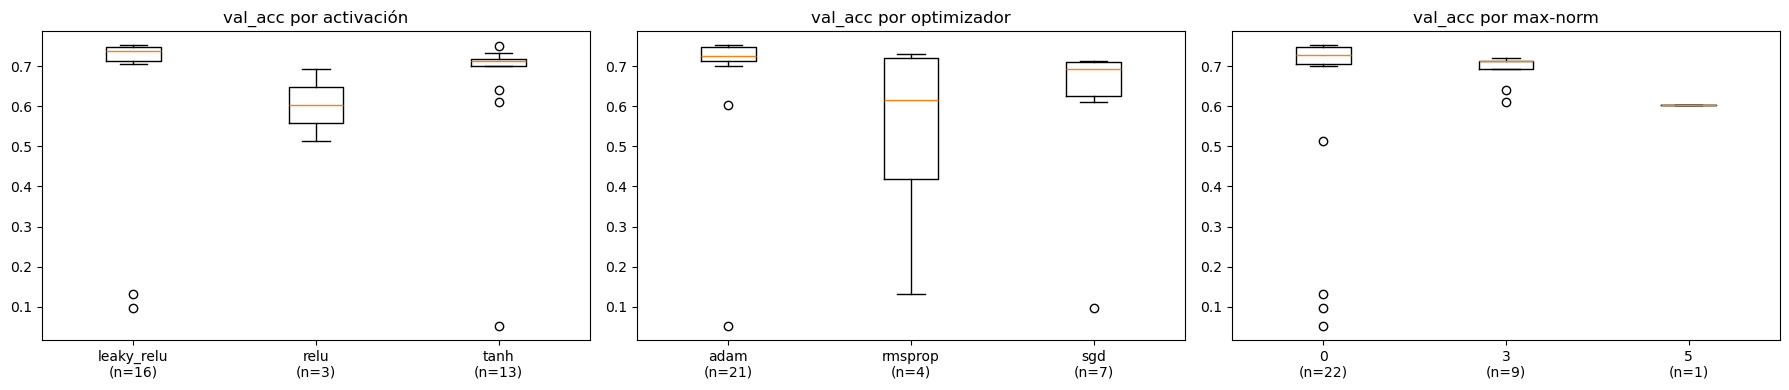

In [49]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

# Historia de la búsqueda
ax = axes[0, 0]
for estado, marca in [("COMPLETE", "o"), ("PRUNED", "x")]:
    d = df_t[df_t["state"] == estado]
    ax.scatter(d["number"], d["value"], marker=marca, label=estado)
mejor_hasta = comp.sort_values("number")["value"].cummax()
ax.step(comp.sort_values("number")["number"], mejor_hasta, where="post", color="k", label="mejor hasta el trial")
ax.set_title("Historia de la búsqueda")
ax.set_xlabel("trial")
ax.set_ylabel("val_acc")
ax.legend(fontsize=8)

# Learning rate (escala log)
ax = axes[0, 1]
for opt_name, d in comp.groupby("params_optimizer"):
    ax.scatter(d["params_lr"], d["value"], label=opt_name)
ax.set_xscale("log")
ax.set_title("val_acc vs. learning rate (trials completos)")
ax.set_xlabel("lr")
ax.legend(fontsize=8)

# Lambdas (escala log)
ax = axes[0, 2]
for col, nom in [("params_l1_lambda", "λ L1"), ("params_l2_lambda", "λ L2")]:
    if col in comp.columns:
        d = comp.dropna(subset=[col])
        ax.scatter(d[col], d["value"], label=nom)
ax.set_xscale("log")
ax.set_title("val_acc vs. λ")
ax.set_xlabel("λ")
ax.legend(fontsize=8)


def cajas(ax, col, titulo):
    if col not in comp.columns:
        return
    grupos = [(str(k), g["value"].values) for k, g in comp.groupby(col)]
    ax.boxplot([v for _, v in grupos])
    ax.set_xticks(range(1, len(grupos) + 1), [f"{k}\n(n={len(v)})" for k, v in grupos])
    ax.set_title(titulo)


cajas(axes[1, 0], "params_reg_type", "val_acc por tipo de regularización")
cajas(axes[1, 1], "params_batchnorm", "val_acc con y sin BatchNorm")
ax = axes[1, 2]
ax.scatter(comp["params_dropout"], comp["value"], c=comp["params_batchnorm"].astype(int), cmap="coolwarm")
ax.set_title("val_acc vs. dropout (rojo = con BatchNorm)")
ax.set_xlabel("dropout")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
cajas(axes[0], "params_activation", "val_acc por activación")
cajas(axes[1], "params_optimizer", "val_acc por optimizador")
cajas(axes[2], "params_max_norm", "val_acc por max-norm")
plt.tight_layout()
plt.show()

### Análisis 10 – Búsqueda de hiperparámetros

**Trials.** Se hicieron **48 trials en 40,2 minutos**: la búsqueda terminó por tiempo, no por llegar a 60. De esos, **32 se completaron y 16 se podaron (33%)**. Los podados duraron una mediana de 8 s contra 26 s de los completos, y en la historia de la búsqueda todos tienen accuracy baja (la mayoría por debajo de 0,5). El pruner cortó intentos malos y ahorró tiempo para probar más combinaciones.

**Mejor trial (40): validación 0,7521.**
- Red: 1 capa de 256, `leaky_relu`, Adam con lr 1,13e-3, beta1 0,924, beta2 0,99974, batch 128.
- Regularización: **dropout 0,51**, sin L1/L2, sin BatchNorm y sin max-norm.
- Preprocesamiento: se sacan las stopwords, stemming, solo palabras sueltas, 10.000 términos, min_df 1.

**Los 10 mejores trials se parecen mucho entre sí:**
- todos tienen 1 capa, Adam, solo palabras sueltas y 10.000 términos;
- 8 usan `leaky_relu` y 2 usan `tanh`;
- **todos usan dropout entre 0,39 y 0,63**;
- ninguno usa BatchNorm;
- solo 2 usan L2, con λ muy chicos (1e-6 y 1,3e-5).

Esto coincide con los barridos: dropout ayuda, L1/L2 no (o solo con λ mínimos), y una red chica funciona mejor que una grande.

**Por tipo de regularización** (trials completos): `none` tiene la mediana más alta (n=14) y `l2` la mayor dispersión (de 0,10 a 0,75, n=7), porque incluye los λ grandes que dejan a la red sin aprender, como en 8.1. Hubo trials con L2 de 6e-3 y 6e-2 que llegaron a ≈0,71, cuando en el barrido L2 1e-2 no aprendía. Pero en Optuna cambian muchas cosas a la vez (red más chica, BN, otro optimizador) y no se puede saber qué lo compensó. Por eso se hicieron los barridos de a una técnica.

**BatchNorm en Optuna** (n=8 con BN, n=24 sin BN) tiene una mediana algo menor que sin BN. En el barrido, en cambio, BN + dropout fue la mejor 2x512. Esta diferencia tampoco se puede interpretar, por el mismo motivo.

**Activación.** No hubo ningún trial completo con `sigmoid` (todos podados o no elegidos). *Hipótesis* coherente con la clase y con el TP2 (donde sigmoid tardó 8 épocas en pasar 70%): sigmoid se satura y da gradientes chicos, así que en las primeras épocas va peor que la mediana y el pruner la corta. `leaky_relu` (n=16) tuvo una mediana de ≈0,74 contra ≈0,60 de `relu`, pero relu tiene solo n=3. *Hipótesis* coherente con la clase: leaky_relu evita las neuronas muertas de ReLU. Con 3 trials no alcanza para afirmarlo.

**Optimizador.** Adam fue el más elegido (n=21, mediana ≈0,73) y el más estable. SGD (n=7) quedó en ≈0,69 y RMSprop (n=4) fue muy disperso.

**Importancia de los hiperparámetros.**
- Los primeros son `l2_lambda` (0,30), `one_minus_beta2` (0,22), `beta1` (0,16), `lr` (0,13) y `dropout` (0,08). El preprocesamiento casi no importa (≤ 0,005 cada uno): coincide con que el TP1 ya había encontrado una buena combinación y los mejores trials la repiten.
- Estos números hay que leerlos con cuidado. `l2_lambda`, `beta1` y `one_minus_beta2` solo existen en una parte de los trials (13 trials con L2 y 21 con Adam). Por ejemplo, la importancia de `l2_lambda` sale sobre todo de que con λ grande la red deja de aprender. Además, son solo 32 trials completos.

**Escalas.** Gracias a la escala log, los valores probados cubren varias décadas: lr de 3e-4 a 8e-2, λ de 1e-7 a 7e-2, y beta2 hasta 0,99974 (1−beta2 = 2,6e-4). Con escala lineal, casi todos habrían caído en la década más alta. Desde el trial ≈22 en adelante, la mayoría de los trials completos queda por encima de 0,70: el sampler TPE se concentró en la zona buena.

## 11. Entrenamiento final y evaluación en test

Se entrenan dos modelos con **el mismo protocolo**, para compararlos con el mismo presupuesto:

1. **TP3**: la mejor configuración de Optuna (incluye su preprocesamiento).
2. **TP2**: la mejor configuración del TP2 (1x64 RMSprop, sin regularización), ahora sin la fuga de información.

Protocolo: se entrena con train, se monitorea `val_loss` y se corta si no mejora en 5 épocas (máximo 30). Después se **recuperan los pesos de la mejor época** (early stopping) y recién ahí se evalúa en test. Se repite con 3 semillas y se informa la mediana y el desvío. El test **no se usó para elegir nada**.

In [50]:
cfg_tp3, pre_tp3 = config_desde_params(study.best_params)
FINALES = {"TP3 mejor Optuna": (cfg_tp3, pre_tp3),
           "TP2 mejor (sin reg.)": (CONFIGS["TP2 mejor (1x64 RMSprop)"], BASE_PREPROC)}
print("Configuración TP3:", cfg_tp3)
print("Preprocesamiento TP3:", pre_tp3)

mlflow.end_run()
mlflow.set_experiment(f"tp3_final_{SUFIJO}")
criterion = nn.CrossEntropyLoss()
filas_final, modelos_final = [], {}

for nombre, (c, pre) in FINALES.items():
    X_tr, X_val, X_te, _ = vectorizar(**pre)
    ds_tr, ds_val, ds_te = a_tensores(X_tr, y_tr), a_tensores(X_val, y_val), a_tensores(X_te, y_test)
    test_loader = DataLoader(ds_te, batch_size=1024, shuffle=False)
    for seed in SEEDS:
        writer = SummaryWriter(f"{RUNS_DIR}/final/{nombre_carpeta(nombre)}_seed{seed}")
        with mlflow.start_run(run_name=f"{nombre}_seed{seed}"):
            h, mejor_estado, model = correr_config(c, ds_tr, ds_val, seed, EPOCHS_FINAL_MAX,
                                                   writer=writer, patience=PATIENCE)
            if mejor_estado is not None:
                model.load_state_dict(mejor_estado)      # pesos de la mejor época (early stopping)
            test_loss, test_acc = evaluar(model, test_loader, criterion)   # test: solo acá
            be = h["mejor_epoca"] if h["mejor_epoca"] is not None else len(h["val_loss"]) - 1
            mlflow.log_params({k: str(v) for k, v in c.items()} | {f"pre_{k}": v for k, v in pre.items()}
                              | {"seed": seed, "patience": PATIENCE})
            for ep in range(len(h["val_loss"])):
                mlflow.log_metrics({"train_loss": h["train_loss"][ep], "val_loss": h["val_loss"][ep],
                                    "val_acc": h["val_acc"][ep]}, step=ep)
            mlflow.log_metrics({"mejor_epoca": be + 1, "val_acc_mejor": h["val_acc"][be],
                                "test_loss": test_loss, "test_acc": test_acc})
            if seed == SEEDS[0]:
                try:
                    mlflow.pytorch.log_model(model, name="modelo", serialization_format="pickle")
                except TypeError:
                    mlflow.pytorch.log_model(model, "modelo", serialization_format="pickle")
                except Exception as e:
                    print("No se pudo guardar el modelo en MLflow:", e)
        writer.close()
        filas_final.append({"modelo": nombre, "seed": seed, "epocas_corridas": len(h["val_loss"]),
                            "mejor_epoca": be + 1, "train_acc_eval": h["train_acc_eval"][be],
                            "val_acc": h["val_acc"][be], "test_acc": test_acc, "test_loss": test_loss,
                            "mean_abs_capa1": h["mean_abs_capas"][be][0],
                            "s_por_epoca": float(np.median(h["epoch_time"][1:])) if len(h["epoch_time"]) > 1
                                           else h["epoch_time"][0]})
        if seed == SEEDS[0]:
            modelos_final[nombre] = (model, test_loader)
        print(f"{nombre} seed {seed}: mejor época {be + 1} | val {h['val_acc'][be]:.4f} | test {test_acc:.4f}")

df_final = pd.DataFrame(filas_final)
print()
print(df_final.round(4).to_string(index=False))
print("\nMediana (desvío) entre semillas:")
agg = df_final.groupby("modelo")[["mejor_epoca", "train_acc_eval", "val_acc", "test_acc", "mean_abs_capa1"]]
print(agg.median().round(4).astype(str).add(" (").add(agg.std().round(4).astype(str)).add(")").to_string())

2026/11/18 13:39:28 INFO mlflow.tracking.fluent: Experiment with name 'tp3_final_completo' does not exist. Creating a new experiment.


Configuración TP3: {'hidden': [256], 'act': 'leaky_relu', 'opt': 'adam', 'lr': 0.0011278256331487544, 'bs': 128, 'opt_kw': {'beta1': 0.9241879220137176, 'beta2': 0.9997376298520861}, 'l1': 0.0, 'l2': 0.0, 'dropout': 0.5098003789801987, 'dropout_in': 0.0, 'bn': False, 'max_norm': 0.0, 'grupo': 'Optuna'}
Preprocesamiento TP3: {'sw': True, 'norm': 'stem', 'ngram': '1gram', 'max_features': 10000, 'min_df': 1}


2026/11/18 13:47:54 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/11/18 13:49:54 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: C:\Users\santi\AppData\Local\Temp\tmp_22yok5z\model\data, flavor: pytorch). Fall back to return ['torch==2.14.0', 'cloudpickle==3.1.1']. Set logging level to DEBUG to see the full traceback. 


TP3 mejor Optuna seed 0: mejor época 9 | val 0.7503 | test 0.6843
TP3 mejor Optuna seed 1: mejor época 10 | val 0.7508 | test 0.6818
TP3 mejor Optuna seed 2: mejor época 9 | val 0.7525 | test 0.6841


2026/11/18 13:57:18 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


TP2 mejor (sin reg.) seed 0: mejor época 9 | val 0.7433 | test 0.6768
TP2 mejor (sin reg.) seed 1: mejor época 8 | val 0.7362 | test 0.6806
TP2 mejor (sin reg.) seed 2: mejor época 8 | val 0.7446 | test 0.6828

              modelo  seed  epocas_corridas  mejor_epoca  train_acc_eval  val_acc  test_acc  test_loss  mean_abs_capa1  s_por_epoca
    TP3 mejor Optuna     0               14            9          0.9570   0.7503    0.6843     1.0871          0.0476      26.4810
    TP3 mejor Optuna     1               15           10          0.9615   0.7508    0.6818     1.0971          0.0495      20.9928
    TP3 mejor Optuna     2               14            9          0.9585   0.7525    0.6841     1.0886          0.0478       1.5206
TP2 mejor (sin reg.)     0               14            9          0.9230   0.7433    0.6768     1.1331          0.0906       1.5457
TP2 mejor (sin reg.)     1               13            8          0.9040   0.7362    0.6806     1.1108          0.0850       8.47

Accuracy en test (TP3, semilla 0): 0.6843

                          precision    recall  f1-score   support

             alt.atheism       0.53      0.49      0.51       319
           comp.graphics       0.59      0.67      0.63       389
 comp.os.ms-windows.misc       0.61      0.62      0.61       394
comp.sys.ibm.pc.hardware       0.64      0.64      0.64       392
   comp.sys.mac.hardware       0.73      0.70      0.71       385
          comp.windows.x       0.80      0.66      0.72       395
            misc.forsale       0.75      0.77      0.76       390
               rec.autos       0.48      0.77      0.60       396
         rec.motorcycles       0.74      0.72      0.73       398
      rec.sport.baseball       0.88      0.82      0.85       397
        rec.sport.hockey       0.90      0.88      0.89       399
               sci.crypt       0.81      0.71      0.76       396
         sci.electronics       0.60      0.58      0.59       393
                 sci.med       0

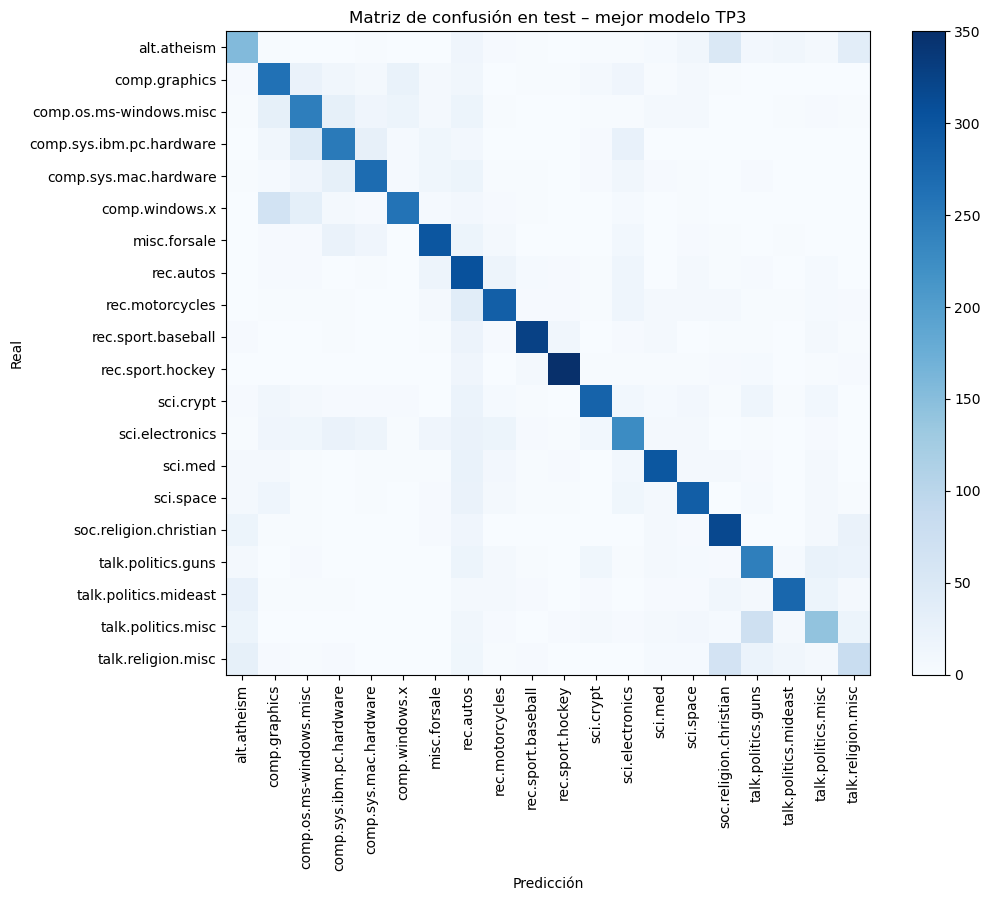

In [51]:
model, test_loader = modelos_final["TP3 mejor Optuna"]
model.eval()
preds, reales = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        preds.extend(model(xb.to(device)).argmax(dim=1).cpu().numpy())
        reales.extend(yb.numpy())
print(f"Accuracy en test (TP3, semilla {SEEDS[0]}): {accuracy_score(reales, preds):.4f}\n")
print(classification_report(reales, preds, labels=list(range(NUM_CLASSES)), target_names=class_names,
                            zero_division=0))

cm = confusion_matrix(reales, preds, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(11, 9))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión en test – mejor modelo TP3")
plt.tight_layout()
plt.show()

### Análisis 11 – Resultado final

| | Validación | Test | Train (modo eval) |
|---|---|---|---|
| TP3 (mejor de Optuna) | 0,7508 (desvío 0,0012) | **0,6841** (0,0014) | 0,9585 |
| TP2 (mejor del TP2, mismo protocolo) | 0,7433 (0,0045) | **0,6806** (0,0030) | 0,9080 |

**TP3 contra TP2.** El modelo del TP3 es mejor en test por **0,35 puntos** (mediana), y es mayor en las 3 semillas (0,6843 / 0,6818 / 0,6841 contra 0,6768 / 0,6806 / 0,6828). La diferencia es chica: del orden de 1 a 2 desvíos entre semillas. Con 3 semillas, no alcanza para afirmar que la mejora sea real y no producto del azar. El entrenamiento final de los dos es comparable: mismos datos, mismo split sin fuga, mismo early stopping (paciencia 5, máximo 30 épocas) y mismas semillas. Lo que no es igual es cómo se eligió cada configuración: la del TP2 salió de su propia búsqueda (25 trials de 8 épocas) y la del TP3 de esta (48 trials de 15 épocas). Por eso, la comparación muestra qué tan buena es cada configuración elegida, no cuál de las dos búsquedas es mejor.

**Sesgo y varianza.** En los dos modelos sigue habiendo **varianza alta**: train ≈0,96 contra validación ≈0,75 en el TP3 (brecha 0,21), y 0,91 contra 0,74 en el TP2 (brecha 0,16). La regularización y el early stopping la reducen, pero no la eliminan.

**Test 6–7 puntos debajo de validación en los dos modelos.** Hay dos posibles causas:
1. Validación se usó para elegir hiperparámetros y la época de corte, así que queda algo optimista.
2. *Hipótesis:* la versión de 20 Newsgroups de scikit-learn separa train y test por fecha (el test tiene mensajes posteriores), así que los temas pueden haber cambiado un poco.

**Por clase.** Las mejores son `rec.sport.hockey` (f1 0,89) y `rec.sport.baseball` (0,85). Las peores son `talk.religion.misc` (0,36), `talk.politics.misc` (0,50) y `alt.atheism` (0,51). En la matriz de confusión se ve que estas se confunden con clases de tema parecido:
- `talk.religion.misc` con `soc.religion.christian` y `alt.atheism`;
- `talk.politics.misc` con `talk.politics.guns`;
- `comp.windows.x` con `comp.graphics`.

`rec.autos` tiene precisión baja (0,48) con recall alto (0,77): recibe predicciones de muchas otras clases (se ve como una columna clara en la matriz).

*Tiempos del entrenamiento final:* las semillas 0 y 1 del TP3 midieron 26,5 y 21,0 s por época, contra 1,52 s de la semilla 2. Es la misma interferencia de la sección 8.3, así que esos tiempos no se usan para sacar conclusiones.

## 12. Conclusiones

**Respuesta a la consigna, técnica por técnica** (red 2x512 con varianza alta: train ≈0,97 y validación 0,711 en su mejor época):

| Técnica | Accuracy de validación | Pesos | Tiempo / convergencia | Learning rate | Ruido |
|---|---|---|---|---|---|
| **L2** | No mejora: 0,691 (1e-4), 0,612 (1e-3). Con 1e-2 o más no aprende (sesgo alto) | Todos se achican: media −65% y −82%. Con 1e-2, 100% < 1e-3 | Mejor época más tarde (11–14 con 1e-3) | — | Con 1e-3, el doble de ruido entre batches |
| **L1** | No mejora: 0,701 (1e-6), 0,657 (1e-5). Con 1e-4 o más no aprende | **Esparsos**: dos grupos de pesos; 59–73% casi cero con un máximo similar a la base | — | — | Similar a la base |
| **L1+L2** | Peor que cada una por separado (0,573) | 74% casi cero | — | — | Alto |
| **Dropout** | **Mejora chica y consistente**: 0,715–0,719, mayor en las 3 semillas | No baja la media, baja el máximo | **Más épocas**: mejor época 3, 4 y 8 | Subir el lr ×10 empeoró (0,695) | Train medida en entrenamiento queda debajo de la medida en evaluación; más ruido con p más alto |
| **BatchNorm** | 0,715 sola; **0,734 con dropout** (mejor 2x512) | Media y máximo −65%, sin penalización | **Menos épocas**: 70% en 1 época | Es la que mejor tolera el lr alto | La curva más suave |

**Lo principal:**
1. En este problema, la regularización que funcionó fue **dropout**, sola o con BatchNorm. Optuna llegó a lo mismo: los 10 mejores trials usan dropout de 0,39 a 0,63 y ninguno usa L1/L2 apreciable.
2. **L1 y L2 no mejoraron con ningún λ probado.** Los λ "razonables" de la clase acá pesan mucho más, porque la penalización suma sobre 5 millones de pesos. Bajar λ las acerca a la base, pero no la supera.
3. Lo que más ayudó fue **achicar la red**, otra de las soluciones de clase para la varianza alta: la mejor configuración es de 1 capa, y la 1x64 del TP2 supera a todas las 2x512 regularizadas.
4. El modelo final del TP3 llega a **0,684 en test** contra 0,681 de la mejor red del TP2 con el mismo protocolo: una mejora chica, que con 3 semillas no se puede confirmar. Sigue habiendo varianza alta (train 0,96 contra validación 0,75).
5. Se confirmaron las observaciones de clase de que dropout pide más épocas y hace más ruidosa la curva de train, que BN acelera la convergencia, y que el sobreajuste, medido con la `val_loss`, viene con pesos grandes. No se confirmó que subir el lr ayude con dropout (hipótesis: porque se usa Adam), ni que BN y dropout no deban combinarse.

### Limitaciones

- Los tiempos se midieron en una sola computadora (CPU) y hubo interrupciones durante la corrida (algunas corridas tardaron 15 a 25 veces lo normal). Por eso las diferencias de segundos por época entre técnicas no son concluyentes. Las conclusiones de velocidad se basan en **cantidad de épocas**, que no depende de eso.
- Optuna corrió 48 trials (32 completos) con una sola semilla por trial. La diferencia entre los mejores trials (0,744 a 0,752) es del orden de la variación entre semillas.
- Los barridos usan una sola red base (2x512 ReLU) con Adam. Con SGD, que es el contexto de varias recomendaciones de clase como la del lr con dropout, los resultados de L2 y del lr podrían ser otros.
- Se usó un mismo λ para todas las capas, y la capa 1 tiene casi todos los pesos (10.000 × 512). La clase menciona que se puede usar un λ distinto por capa; eso podría dar mejores resultados con L1/L2 y no se probó.
- La accuracy de validación se usó para elegir todo, así que es optimista. El valor que se informa como resultado es el de test.

## 13. Reproducibilidad

### requirements.txt

La celda de abajo escribe `requirements.txt` con las **versiones exactas instaladas en este entorno**. No se incluyen `torchvision` ni `torchaudio` porque este TP no los usa; así no hay riesgo de que queden versiones incompatibles con `torch`.

In [52]:
from importlib.metadata import version, PackageNotFoundError

paquetes = ["torch", "numpy", "pandas", "scikit-learn", "matplotlib", "nltk", "optuna", "mlflow", "tensorboard"]
lineas = [f"# Python {platform.python_version()} – generado por el notebook TP3"]
for p in paquetes:
    try:
        v = version(p)
    except PackageNotFoundError:
        print("No instalado:", p)
        continue
    if p == "torch" and "+" in v:      # ej. 2.5.1+cpu: necesita el índice de PyTorch para instalarse
        lineas.insert(1, "--extra-index-url https://download.pytorch.org/whl/cpu")
    lineas.append(f"{p}=={v}")
with open("requirements.txt", "w") as f:
    f.write("\n".join(lineas) + "\n")
print(open("requirements.txt").read())

# Python 3.13.9 – generado por el notebook TP3
torch==2.14.0
numpy==2.3.5
pandas==2.3.3
scikit-learn==1.7.2
matplotlib==3.10.6
nltk==3.9.2
optuna==5.0.0
mlflow==3.16.1
tensorboard==2.21.0



### TensorBoard

Para abrirlo, desde el **Anaconda Prompt**, en la carpeta del repo:

```
tensorboard --logdir runs
```

y entrar a http://localhost:6006. En `runs/tp3_completo/barridos/` hay una carpeta por configuración de los barridos (semilla 0), con curvas, tiempos y media de |w| por capa (pestaña *Scalars*) e histogramas de los pesos por época (pestañas *Histograms* y *Distributions*). En `runs/tp3_completo/final/` están los entrenamientos finales.

Capturas:

![TensorBoard – curvas](img/tensorboard_curvas.png)

![TensorBoard – histogramas de pesos](img/tensorboard_histogramas.png)